# **Proyecto. Estadística Bayesiana - Pensamiento Crítico 2 - 2026-2.**
## **Ciencia de Datos - Departamento de Matemáticas.**
___
### 🪙 **Título:** Análisis de la severidad de la pérdida (LGD) y su asociación con las características de los créditos en default de Happen Bank (LendingClub, 2007–2018).


### 💰 **Base de Datos:** All Lending Club Loan Data.
#### Integrantes:
* Daira Julieth Campos Vásquez.
* María Camila Cárdenas Cañón.
* Alejandro José Medina Cárdenas
#### Docentes:
* Diana Carolina Moreno Chavarro.
* Diana Angelina Pulido López.

### **Cómo leer este cuaderno.**

El cuaderno se lee de arriba hacia abajo, en el mismo orden en que se hizo el análisis:

| Sección | Qué se hace | Resultado |
|---|---|---|
| **1. Base de datos** | Carga desde Kaggle y, problema por problema: filas que no son créditos, faltantes en la LGD, censura del target (ventana de 15 meses), créditos fuera de política, valores imposibles y duplicados | `df_def` (castigados), `df_modelo` (tras la ventana), `df_ajuste` (base del modelo) |
| **2. EDA** | Distribuciones, pérdida por calificación, plazo y propósito, atípicos por calificación, correlaciones (Spearman y Pearson), utilización del crédito y tasas que no corresponden a su calificación | Variables candidatas al modelo |
| **3. Modelo** | Pipeline, problema de multicolinealidad, priors, especificación bayesiana, Gibbs, validación cruzada temporal, convergencia, posterior, prueba 2015, incertidumbre de los resultados, análisis exploratorio y tabla final | Veredicto frente a los criterios de éxito |

Cada problema de los datos o del modelo tiene un markdown que empieza con **"Problema"**: explica qué es, cómo se detecta y qué se decidió, y debajo va todo su código.

Todas las cifras con incertidumbre se reportan con su **intervalo de credibilidad del 95 %** (percentiles 2,5 y 97,5 de las muestras de la posterior) o, cuando la incertidumbre viene de la muestra, con su **intervalo bootstrap del 95 %**.

## **1. Sobre la Base de Datos: Información general.**

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import kagglehub
import glob
import os

In [2]:
# Semilla: hace reproducible todo lo que usa números aleatorios (muestreo de Gibbs, submuestras de gráficos)
semilla = 2026
rng = np.random.default_rng(semilla)

In [3]:
# Variables que se cargan (16 de las 151) y su nombre en español
traduccion = {
    'id': 'id_prestamo', 'loan_status': 'estado', 'funded_amnt': 'monto',
    'total_rec_prncp': 'capital_pagado', 'recoveries': 'recuperacion',
    'collection_recovery_fee': 'comision', 'int_rate': 'tasa', 'annual_inc': 'ingreso',
    'dti': 'dti', 'grade': 'calificacion', 'term': 'plazo', 'purpose': 'proposito',
    'issue_d': 'fecha_originacion', 'last_pymnt_d': 'fecha_ultimo_pago',
    'installment': 'cuota', 'total_pymnt': 'total_pagado',
}

In [4]:
# Estados del crédito en español; los dos que empiezan por "Castigado" son la población del estudio
estados = {
    'Charged Off': 'Castigado',
    'Does not meet the credit policy. Status:Charged Off': 'Castigado (fuera de política)',
    'Fully Paid': 'Pagado totalmente',
    'Does not meet the credit policy. Status:Fully Paid': 'Pagado (fuera de política)',
    'Current': 'Al día', 'In Grace Period': 'En periodo de gracia',
    'Late (16-30 days)': 'En mora (16-30 días)', 'Late (31-120 days)': 'En mora (31-120 días)',
    'Default': 'En incumplimiento',
}

In [5]:
# El plazo viene con un espacio adelante (' 36 months'), por eso están las dos versiones
plazos = {' 36 months': '36 meses', ' 60 months': '60 meses', '36 months': '36 meses', '60 months': '60 meses'}

In [6]:
propositos = {
    'debt_consolidation': 'Consolidación de deudas', 'credit_card': 'Tarjeta de crédito',
    'home_improvement': 'Mejoras del hogar', 'major_purchase': 'Compra importante',
    'small_business': 'Pequeño negocio', 'car': 'Vehículo', 'medical': 'Gastos médicos',
    'moving': 'Mudanza', 'vacation': 'Vacaciones', 'house': 'Vivienda', 'wedding': 'Boda',
    'renewable_energy': 'Energía renovable', 'educational': 'Educación', 'other': 'Otro',
}

In [ ]:
# Fuente de datos: la copia versionada del proyecto en Google Drive (descarga original del 26 de octubre de 2026).
# Si no se encuentra, se descarga de Kaggle. La copia se crea una sola vez con Proyecto_LGD_VersionadoBase.ipynb.
RUTA_VERSIONADA = '/content/drive/MyDrive/LGD_Base_Versionada/lending_club_accepted_2007_2018Q4.parquet'
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    print('Sin Google Drive: se usará Kaggle si la copia versionada no está disponible')

In [ ]:
# Carga las columnas pedidas desde la copia versionada o, si no existe, desde Kaggle
def cargar_base(columnas):
    if os.path.exists(RUTA_VERSIONADA):
        print(f'Fuente: copia versionada ({RUTA_VERSIONADA})')
        return pd.read_parquet(RUTA_VERSIONADA, columns=columnas)
    print('Fuente: Kaggle (no se encontró la copia versionada)')
    carpeta = kagglehub.dataset_download('wordsforthewise/lending-club')
    candidatos = [a for a in glob.glob(os.path.join(carpeta, '**', 'accepted_2007_to_2018*.csv*'), recursive=True) if os.path.isfile(a)]
    ruta = sorted(candidatos, key=lambda a: not a.endswith('.gz'))[0]
    return pd.read_csv(ruta, usecols=columnas, dtype={'id': str}, low_memory=False)

In [ ]:
# Carga de las 16 columnas (desde la copia versionada o desde Kaggle)
df = cargar_base(list(traduccion.keys()))
df.shape

In [10]:
# Control de integridad: la base completa tiene 2.260.701 filas
if df.shape[0] < 2_000_000:
    raise ValueError(f'Base incompleta: {df.shape[0]:,} filas. Vuelva a descargarla.')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Data columns (total 16 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   id                       object 
 1   funded_amnt              float64
 2   term                     object 
 3   int_rate                 float64
 4   installment              float64
 5   grade                    object 
 6   annual_inc               float64
 7   issue_d                  object 
 8   loan_status              object 
 9   purpose                  object 
 10  dti                      float64
 11  total_pymnt              float64
 12  total_rec_prncp          float64
 13  recoveries               float64
 14  collection_recovery_fee  float64
 15  last_pymnt_d             object 
dtypes: float64(9), object(7)
memory usage: 276.0+ MB


### **1.1. Limpieza de la Base de Datos.**

#### **Problema: filas que no son créditos y registros repetidos.**

El archivo de Kaggle trae al final filas de resumen (por ejemplo, *"Total amount funded in policy code 1"*) que no son créditos: su identificador no es un número y casi todas sus columnas están vacías. Si se dejan, se cuentan como créditos. **Cómo se detecta:** se convierte el `id` a número y las filas que no se pueden convertir son las de resumen (33). **Qué se decide:** se eliminan, y se verifica que ningún crédito aparezca dos veces.

In [12]:
# Filas que no son créditos: resúmenes al final del archivo, su id no es un número
id_numerico = pd.to_numeric(df['id'], errors='coerce')
df[id_numerico.isna()]

,id,funded_amnt,term,int_rate,installment,grade,annual_inc,issue_d,loan_status,purpose,dti,total_pymnt,total_rec_prncp,recoveries,collection_recovery_fee,last_pymnt_d
421095,Total amount funded in policy code 1: 6417608175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
421096,Total amount funded in policy code 2: 1944088810,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
528961,Total amount funded in policy code 1: 1741781700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
528962,Total amount funded in policy code 2: 564202131,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
651664,Total amount funded in policy code 1: 1791201400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
651665,Total amount funded in policy code 2: 651669342,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
749520,Total amount funded in policy code 1: 1443412975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
749521,Total amount funded in policy code 2: 511988838,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
877716,Total amount funded in policy code 1: 2063142975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
877717,Total amount funded in policy code 2: 823319310,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df = df[id_numerico.notna()].reset_index(drop=True)
df.shape

(2260668, 16)

In [14]:
# Créditos repetidos (por id del crédito)
df['id'].duplicated().sum()

np.int64(0)

In [15]:
# Nombres en español
df = df.rename(columns=traduccion)
df.columns.tolist()

['id_prestamo',
 'monto',
 'plazo',
 'tasa',
 'cuota',
 'calificacion',
 'ingreso',
 'fecha_originacion',
 'estado',
 'proposito',
 'dti',
 'total_pagado',
 'capital_pagado',
 'recuperacion',
 'comision',
 'fecha_ultimo_pago']

In [16]:
# Categorías en español
df['estado'] = df['estado'].map(estados)
df['plazo'] = df['plazo'].map(plazos)
df['proposito'] = df['proposito'].map(propositos)

In [17]:
# Fechas: de texto ('Dec-2015') a fecha real
df['fecha_originacion'] = pd.to_datetime(df['fecha_originacion'], format='%b-%Y')
df['fecha_ultimo_pago'] = pd.to_datetime(df['fecha_ultimo_pago'], format='%b-%Y')

In [18]:
# Distribución de estados (NaN indicaría una categoría sin traducir)
df['estado'].value_counts(dropna=False)

,count
estado,
Pagado totalmente,1076751
Al día,878317
Castigado,268559
En mora (31-120 días),21467
En periodo de gracia,8436
En mora (16-30 días),4349
Pagado (fuera de política),1988
Castigado (fuera de política),761
En incumplimiento,40


In [19]:
df['estado'].value_counts(normalize=True, dropna=False) * 100

,proportion
estado,
Pagado totalmente,47.629771
Al día,38.852100
Castigado,11.879630
En mora (31-120 días),0.949587
En periodo de gracia,0.373164
En mora (16-30 días),0.192377
Pagado (fuera de política),0.087939
Castigado (fuera de política),0.033663
En incumplimiento,0.001769


### **1.2 Creación de la columna LGD.**


In [20]:
# Población: solo créditos castigados (incluye fuera de política). Se excluyen los 40 'En incumplimiento':
# todavía no se castigan, su pérdida no es definitiva
df_def = df[df['estado'].str.startswith('Castigado', na=False)].copy()
df_def['estado'].value_counts()

,count
estado,
Castigado,268559
Castigado (fuera de política),761


#### **Problema: valores faltantes en los componentes de la LGD.**

La LGD se calcula con cuatro variables (monto, capital pagado, recuperación y comisión). Si alguna está vacía o el monto no es positivo, la LGD no se puede calcular o queda mal definida. **Qué se decide (A2-Paso 3):** se excluye el registro, sin imputar valores. En los castigados no hubo ninguno.

In [21]:
# Avance 2, Paso 3: se excluye el registro si falta algún componente de la LGD o si el monto no es positivo
completos = df_def[['monto', 'capital_pagado', 'recuperacion', 'comision']].notna().all(axis=1) & (df_def['monto'] > 0)
print(f'Castigados excluidos por componentes vacíos o monto <= 0: {(~completos).sum():,}')

Castigados excluidos por componentes vacíos o monto <= 0: 0


In [22]:
df_def = df_def[completos].copy()
len(df_def)

269320

In [23]:
# lgd = (saldo al default - recuperación neta) / monto, acotada entre 0 y 1
df_def['lgd'] = ((df_def['monto'] - df_def['capital_pagado'] - (df_def['recuperacion'] - df_def['comision'])) / df_def['monto']).clip(0, 1)
df_def['lgd'].describe()

,lgd
count,269320.000000
mean,0.634420
std,0.214975
min,0.000000
25%,0.497344
50%,0.676457
75%,0.801428
max,1.000000


#### **Problema: censura del target (recuperaciones incompletas).**

La recuperación ocurre durante meses después del castigo. Un crédito castigado poco antes del cierre de la base todavía no termina de recuperar, así que su LGD aparece **más alta de lo que será**. Si se usan esos créditos, el modelo aprende pérdidas infladas.

**Cómo se trata:**
1. **Fecha de corte:** el último pago registrado en toda la base (marzo de 2019).
2. **Fecha de default:** se aproxima con el último pago (si nunca pagó, la fecha de originación), y se contrasta con la fecha estimada por cuotas pagadas: coinciden con diferencia de 6 meses o menos en el 99,4 % de los créditos.
3. **Ventana de maduración:** con la curva de recuperación se identifica que la recuperación se estabiliza alrededor de los 15 meses. Solo se conservan los créditos con al menos 15 meses desde el default (excluye 72.917 y deja 196.403).
4. **Cohortes incompletas:** 2016 y 2017 solo conservan los créditos que cayeron en default pronto, por eso no se usan para ajustar ni evaluar el modelo.

In [24]:
# Censura del target. Fecha de corte: último pago registrado en toda la base
fecha_corte = df['fecha_ultimo_pago'].max()
fecha_corte

Timestamp('2019-03-01 00:00:00')

In [25]:
# Fecha de default ≈ último pago; si nunca pagó, fecha de originación
df_def['fecha_default'] = df_def['fecha_ultimo_pago'].fillna(df_def['fecha_originacion'])
df_def['fecha_ultimo_pago'].isna().sum()

np.int64(2325)

In [26]:
# Meses que tuvo cada crédito para recuperar, hasta la fecha de corte
df_def['meses_desde_default'] = (fecha_corte.year - df_def['fecha_default'].dt.year) * 12 + (fecha_corte.month - df_def['fecha_default'].dt.month)
df_def['anio_originacion'] = df_def['fecha_originacion'].dt.year
df_def['meses_desde_default'].describe()

,meses_desde_default
count,269320.000000
mean,27.111399
std,17.887211
min,0.000000
25%,14.000000
50%,24.000000
75%,36.000000
max,135.000000


In [27]:
# Contraste de la fecha de default con la fecha estimada por cuotas pagadas
plazo_meses = df_def['plazo'].str.extract(r'(\d+)')[0].astype(float)
cuotas_pagadas = ((df_def['total_pagado'] - df_def['recuperacion']) / df_def['cuota']).round().clip(0, plazo_meses)
mes = lambda f: f.dt.year * 12 + f.dt.month
mes_por_cuotas = mes(df_def['fecha_originacion']) + cuotas_pagadas
con_fecha = df_def['fecha_ultimo_pago'].notna()
diferencia = (mes(df_def['fecha_ultimo_pago']) - mes_por_cuotas)[con_fecha]
diferencia.describe()

,0
count,266995.000000
mean,0.490455
std,1.699131
min,-47.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,30.000000


In [28]:
tramos = pd.cut(diferencia, bins=[-np.inf, -7, -1, 0, 6, np.inf],
                labels=['Más de 6 meses antes', 'De 1 a 6 meses antes', 'Mismo mes',
                        'De 1 a 6 meses después', 'Más de 6 meses después'])
tabla_tramos = tramos.value_counts().reindex(tramos.cat.categories)
pd.DataFrame({'Créditos': tabla_tramos, '%': (tabla_tramos / len(diferencia) * 100).round(1)})

,Créditos,%
Más de 6 meses antes,1336,0.5
De 1 a 6 meses antes,4984,1.9
Mismo mes,171868,64.4
De 1 a 6 meses después,88420,33.1
Más de 6 meses después,387,0.1


In [29]:
print(f'Diferencia de 6 meses o menos en cualquier dirección: {(diferencia.abs() <= 6).mean() * 100:.1f} %')

Diferencia de 6 meses o menos en cualquier dirección: 99.4 %


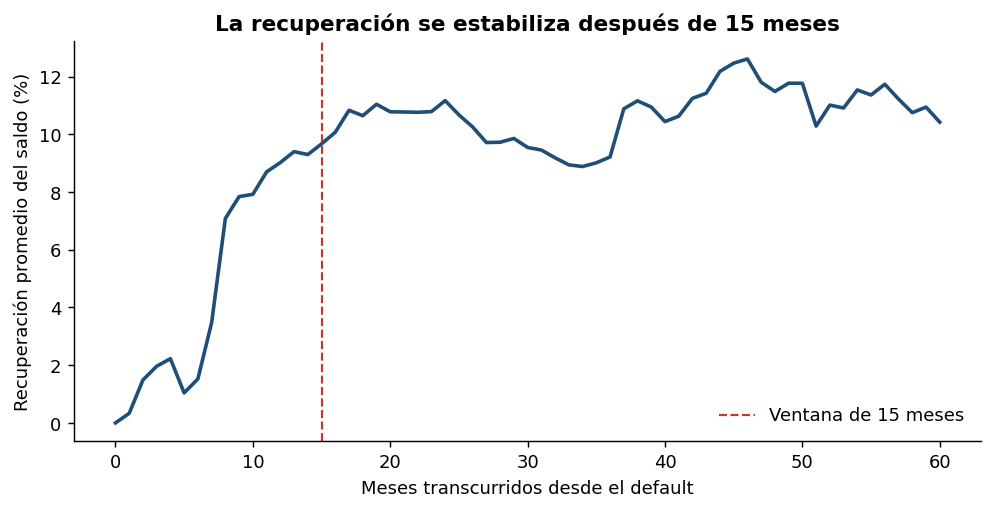

In [30]:
# Curva de recuperación: base para elegir la ventana de maduración
saldo_default = df_def['monto'] - df_def['capital_pagado']
tasa_recuperacion = ((df_def['recuperacion'] - df_def['comision']) / saldo_default).where(saldo_default > 0).clip(0, 1)
curva = (tasa_recuperacion.groupby(df_def['meses_desde_default']).mean() * 100).loc[0:60]

fig, ax = plt.subplots(figsize=(9, 4), dpi=130)
ax.plot(curva.index, curva.values, color='#1f4e79', linewidth=2)
ax.axvline(15, color='#c0392b', linestyle='--', linewidth=1.2, label='Ventana de 15 meses')
ax.set_title('La recuperación se estabiliza después de 15 meses', fontweight='bold')
ax.set_xlabel('Meses transcurridos desde el default')
ax.set_ylabel('Recuperación promedio del saldo (%)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.show()

In [31]:
# Ventana de maduración: solo créditos con 15 meses o más para recuperar
ventana = 15
df_modelo = df_def[df_def['meses_desde_default'] >= ventana].reset_index(drop=True)
len(df_modelo)

196403

In [32]:
print(f'Excluidos por la ventana: {len(df_def) - len(df_modelo):,} ({(len(df_def) - len(df_modelo)) / len(df_def) * 100:.1f} %)')

Excluidos por la ventana: 72,917 (27.1 %)


In [33]:
# Créditos por año de originación antes y después de la ventana (2016-2017 quedan incompletos)
por_anio = pd.DataFrame({
    'Castigados': df_def.groupby('anio_originacion').size(),
    'Después de la ventana': df_modelo.groupby('anio_originacion').size(),
}).fillna(0).astype(int)
por_anio['% que queda'] = (por_anio['Después de la ventana'] / por_anio['Castigados'] * 100).round(1)
por_anio

,Castigados,Después de la ventana,% que queda
anio_originacion,,,
2007,158,158,100.0
2008,496,496,100.0
2009,723,723,100.0
2010,1757,1757,100.0
2011,3297,3297,100.0
2012,8644,8641,100.0
2013,21024,20746,98.7
2014,41161,39357,95.6
2015,75803,64847,85.5


#### **Problema: créditos castigados fuera de política.**

LendingClub marca 761 créditos como *"Does not meet the credit policy. Status: Charged Off"*: castigos reales de créditos otorgados entre 2007 y 2010 con reglas anteriores a la política vigente. **Qué se revisa:** sus años y su LGD frente a los castigados del mismo periodo. **Qué se decide:** se mantienen, porque son castigos reales calculados con la misma fórmula y son el 0,4 % de la base.

In [34]:
# Castigados fuera de política: años y lgd frente a los castigados del mismo periodo
fuera = df_modelo[df_modelo['estado'] == 'Castigado (fuera de política)']
fuera['anio_originacion'].value_counts().sort_index()

,count
anio_originacion,
2007,113
2008,249
2009,129
2010,270


In [35]:
df_modelo[df_modelo['anio_originacion'].isin(fuera['anio_originacion'].unique())].groupby('estado')['lgd'].agg(['count', 'mean', 'median'])

,count,mean,median
estado,,,
Castigado,2373,0.580859,0.621010
Castigado (fuera de política),761,0.625909,0.679328


#### **Problema: valores imposibles o extremos en las predictoras.**

Un ingreso de 0 o negativo no tiene logaritmo, una relación deuda/ingreso vacía no se puede usar en el modelo y una mayor que 100 (deudas mayores al ingreso anual) corresponde a valores atípicos. **Qué se decide (A2-Paso 3):** se excluyen del ajuste (39 créditos: ninguno en entrenamiento, uno en prueba y 38 en 2016–2017). `df_modelo` se conserva para el análisis descriptivo y `df_ajuste` es la base del modelo.

In [36]:
# Exclusiones para el ajuste (Avance 2, Paso 3). Cada motivo por separado (un crédito puede tener varios)
motivos = pd.DataFrame({
    'Ingreso de 0 o menos (sin logaritmo)': df_modelo['ingreso'] <= 0,
    'dti vacío': df_modelo['dti'].isna(),
    'dti mayor que 100': df_modelo['dti'] > 100,
    'Calificación, plazo, propósito o fecha vacíos': df_modelo[['calificacion', 'plazo', 'proposito', 'fecha_originacion']].isna().any(axis=1),
})
motivos.sum()

,0
Ingreso de 0 o menos (sin logaritmo),13
dti vacío,13
dti mayor que 100,26
"Calificación, plazo, propósito o fecha vacíos",0


In [37]:
excluir = motivos.any(axis=1)
print(f'Total de créditos excluidos para el ajuste: {excluir.sum():,}')

Total de créditos excluidos para el ajuste: 39


In [38]:
df_ajuste = df_modelo[~excluir].reset_index(drop=True)
len(df_ajuste)

196364

In [39]:
# Verificación del Paso 3 del Avance 2: faltantes de cada variable en cada etapa (en df_ajuste todo debe dar 0)
variables_paso3 = ['monto', 'capital_pagado', 'recuperacion', 'comision', 'estado', 'tasa', 'ingreso', 'dti',
                   'calificacion', 'plazo', 'proposito', 'fecha_originacion', 'lgd']
pd.DataFrame({'Castigados (df_def)': df_def[variables_paso3].isna().sum(),
              'Tras la ventana (df_modelo)': df_modelo[variables_paso3].isna().sum(),
              'Base de ajuste (df_ajuste)': df_ajuste[variables_paso3].isna().sum()})

,Castigados (df_def),Tras la ventana (df_modelo),Base de ajuste (df_ajuste)
monto,0,0,0
capital_pagado,0,0,0
recuperacion,0,0,0
comision,0,0,0
estado,0,0,0
tasa,0,0,0
ingreso,0,0,0
dti,71,13,0
calificacion,0,0,0
plazo,0,0,0


In [40]:
# Verificación: en la base de ajuste ya no quedan ingresos <= 0 ni dti > 100 (debe dar 0 y 0)
print((df_ajuste['ingreso'] <= 0).sum(), (df_ajuste['dti'] > 100).sum())

0 0


Duplicidad de cuentas

In [41]:
# member_id viene vacío en toda la base, así que no se puede identificar al prestatario.
# Se revisan créditos repetidos y créditos con exactamente las mismas características (posibles cuentas duplicadas)
print(f"id repetidos en df_ajuste: {df_ajuste['id_prestamo'].duplicated().sum():,}")

id repetidos en df_ajuste: 0


In [42]:
caracteristicas = ['monto', 'ingreso', 'dti', 'calificacion', 'plazo', 'proposito', 'fecha_originacion', 'tasa', 'cuota']
iguales = df_ajuste.duplicated(subset=caracteristicas, keep=False)
print(f'Créditos con características idénticas a otro: {iguales.sum():,}')

Créditos con características idénticas a otro: 0


In [43]:
df_ajuste[iguales].sort_values(caracteristicas).head(10)

,id_prestamo,monto,plazo,tasa,cuota,calificacion,ingreso,fecha_originacion,estado,proposito,dti,total_pagado,capital_pagado,recuperacion,comision,fecha_ultimo_pago,lgd,fecha_default,meses_desde_default,anio_originacion


## **2. EDA (Análisis Exploratorio de los Datos).**

In [44]:
# Estilo de los gráficos: alta resolución, sin bordes superiores, etiquetas en español
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 130, 'savefig.dpi': 300, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
orden_calificacion = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
porcentaje = mtick.PercentFormatter(xmax=1)

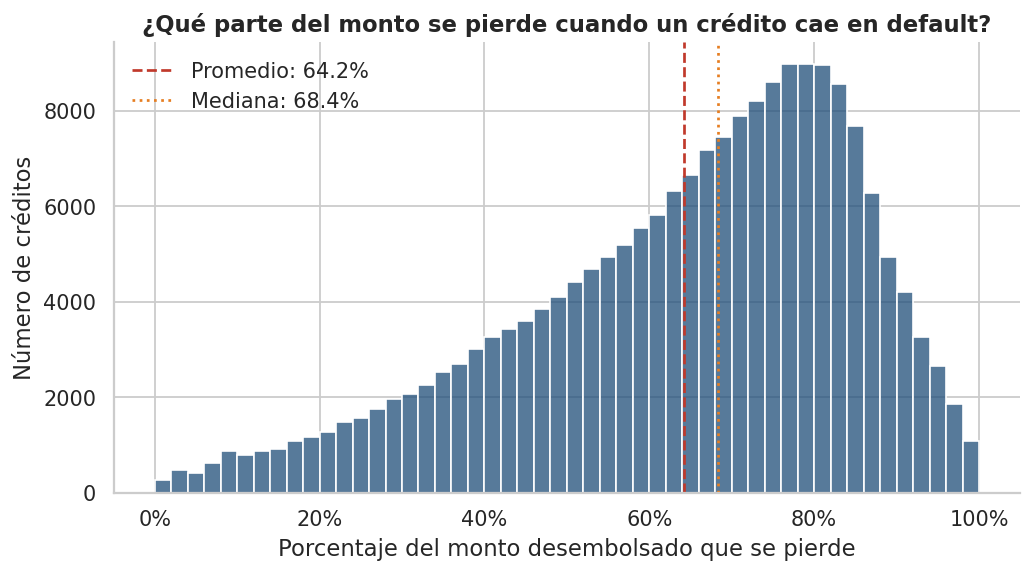

In [45]:
# Distribución de la pérdida (población del estudio: df_modelo)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df_modelo['lgd'], bins=50, color='#1f4e79', edgecolor='white', ax=ax)
ax.axvline(df_modelo['lgd'].mean(), color='#c0392b', linestyle='--', label=f"Promedio: {df_modelo['lgd'].mean():.1%}")
ax.axvline(df_modelo['lgd'].median(), color='#e67e22', linestyle=':', label=f"Mediana: {df_modelo['lgd'].median():.1%}")
ax.xaxis.set_major_formatter(porcentaje)
ax.set_title('¿Qué parte del monto se pierde cuando un crédito cae en default?')
ax.set_xlabel('Porcentaje del monto desembolsado que se pierde')
ax.set_ylabel('Número de créditos')
ax.legend(frameon=False)
plt.show()

In [46]:
# Resumen de las variables numéricas, con títulos ejecutivos
resumen = df_modelo[['lgd', 'monto', 'tasa', 'ingreso', 'dti']].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
resumen['cv (%)'] = resumen['std'] / resumen['mean'] * 100
resumen.index = ['Pérdida (proporción del monto)', 'Monto desembolsado (USD)', 'Tasa de interés (%)',
                 'Ingreso anual (USD)', 'Deuda frente al ingreso (%)']
resumen.columns = ['Créditos', 'Promedio', 'Desviación', 'Mínimo', 'Percentil 25', 'Mediana', 'Percentil 75', 'Máximo', 'Coef. de variación (%)']
resumen.round(2)

,Créditos,Promedio,Desviación,Mínimo,Percentil 25,Mediana,Percentil 75,Máximo,Coef. de variación (%)
Pérdida (proporción del monto),196403.0,0.64,0.21,0.00,0.51,0.68,0.80,1.00,32.28
Monto desembolsado (USD),196403.0,15372.17,8646.79,500.00,8875.00,14000.00,20000.00,40000.00,56.25
Tasa de interés (%),196403.0,15.73,4.73,5.32,12.49,15.31,18.55,30.99,30.07
Ingreso anual (USD),196403.0,69653.05,63905.37,0.00,43000.00,60000.00,83500.00,8900060.00,91.75
Deuda frente al ingreso (%),196390.0,20.04,9.33,0.00,13.63,19.78,26.25,999.00,46.56


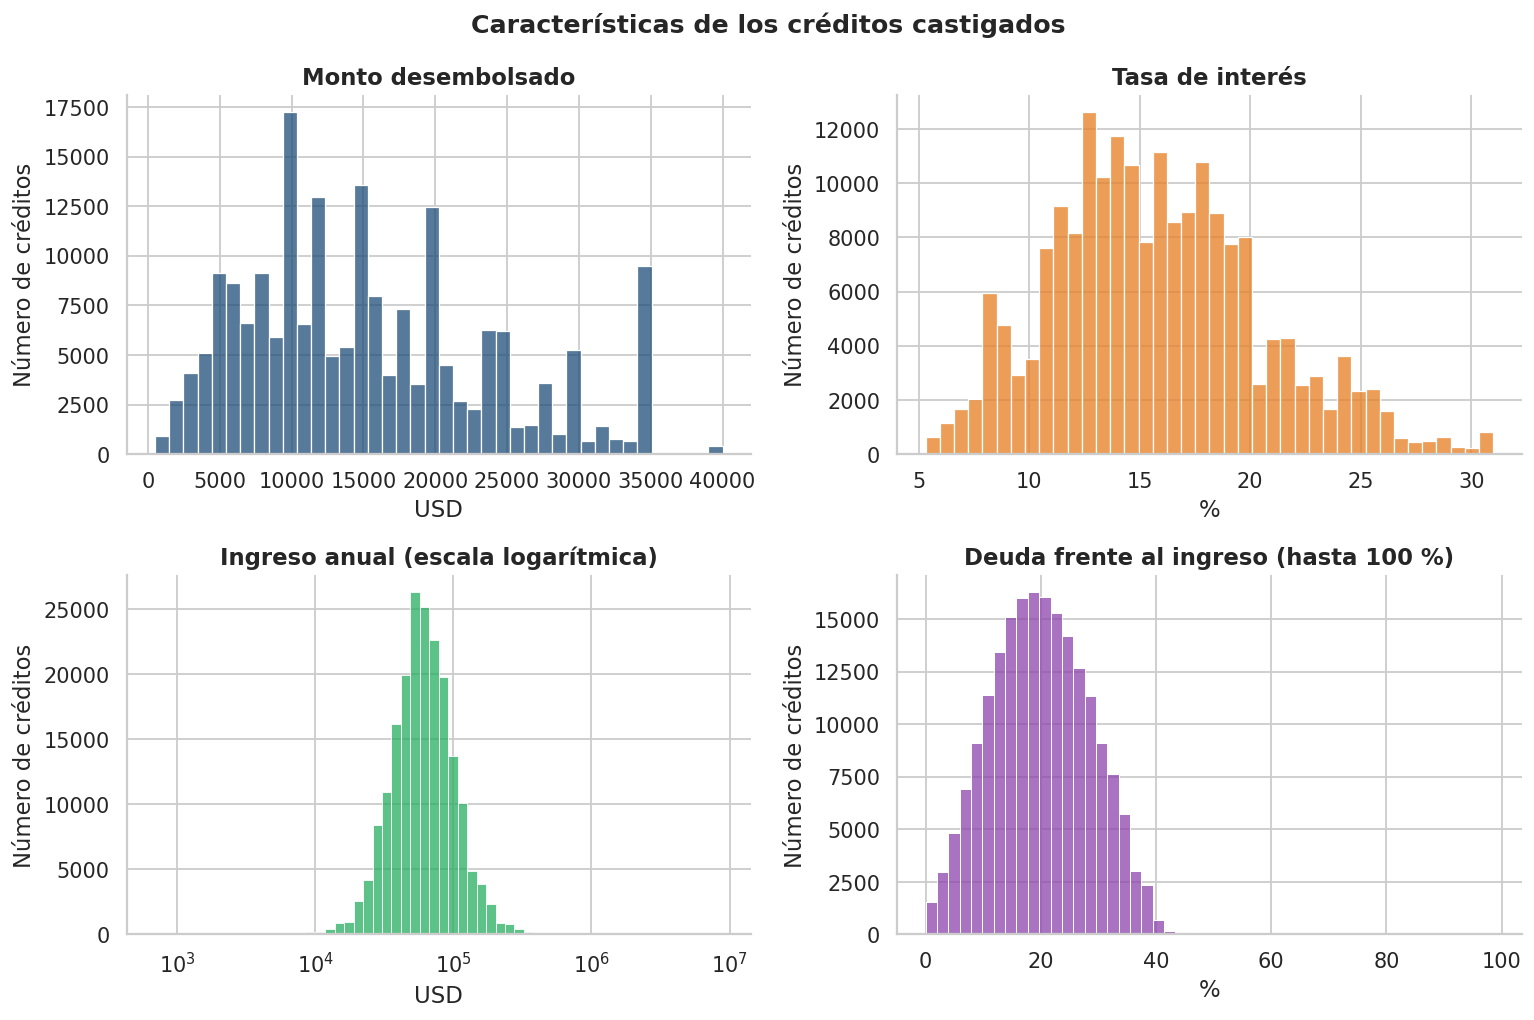

In [47]:
# Distribución de las variables explicativas
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df_modelo['monto'], bins=40, color='#1f4e79', ax=ejes[0, 0])
ejes[0, 0].set_title('Monto desembolsado')
ejes[0, 0].set_xlabel('USD')
sns.histplot(df_modelo['tasa'], bins=40, color='#e67e22', ax=ejes[0, 1])
ejes[0, 1].set_title('Tasa de interés')
ejes[0, 1].set_xlabel('%')
sns.histplot(df_modelo.loc[df_modelo['ingreso'] > 0, 'ingreso'], bins=60, log_scale=True, color='#27ae60', ax=ejes[1, 0])
ejes[1, 0].set_title('Ingreso anual (escala logarítmica)')
ejes[1, 0].set_xlabel('USD')
sns.histplot(df_modelo.loc[df_modelo['dti'] <= 100, 'dti'], bins=50, color='#8e44ad', ax=ejes[1, 1])
ejes[1, 1].set_title('Deuda frente al ingreso (hasta 100 %)')
ejes[1, 1].set_xlabel('%')
for eje in ejes.flat:
    eje.set_ylabel('Número de créditos')
fig.suptitle('Características de los créditos castigados', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

In [48]:
# Cifra del fenómeno: pérdida por calificación sobre TODOS los castigados (df_def)
fenomeno = df_def.groupby('calificacion')['lgd'].agg(['count', 'mean'])
print(f"Diferencia de pérdida promedio entre G y A: {(fenomeno.loc['G', 'mean'] - fenomeno.loc['A', 'mean']) * 100:.1f} puntos porcentuales")

Diferencia de pérdida promedio entre G y A: 23.6 puntos porcentuales


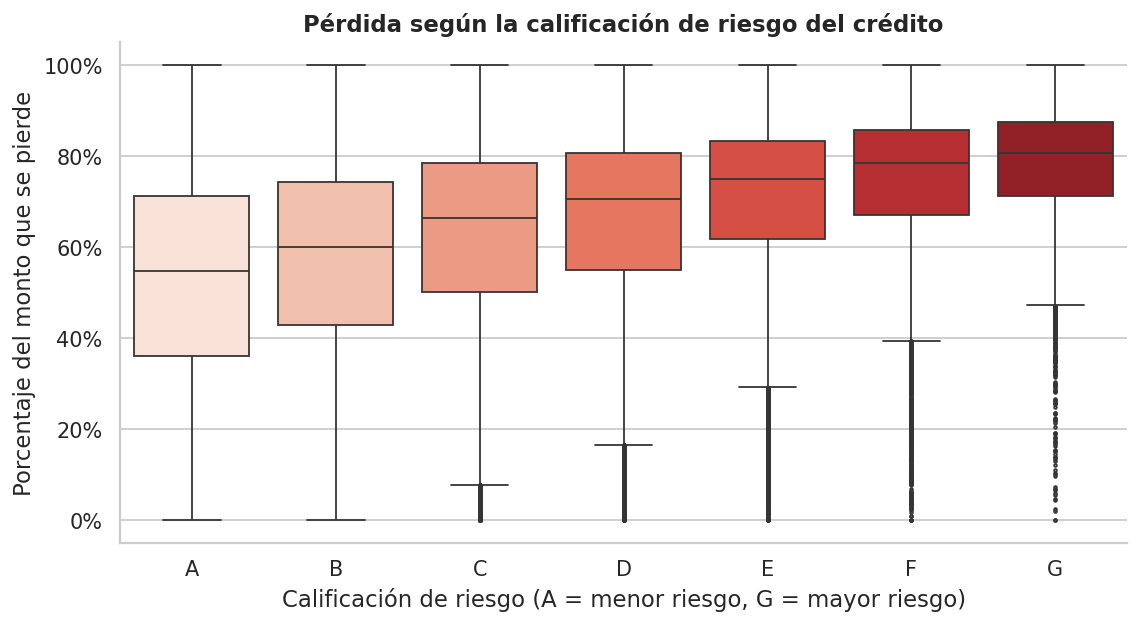

In [49]:
# Pérdida por calificación de riesgo
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_modelo, x='calificacion', y='lgd', order=orden_calificacion, hue='calificacion',
            hue_order=orden_calificacion, palette='Reds', legend=False, fliersize=1.5, ax=ax)
ax.yaxis.set_major_formatter(porcentaje)
ax.set_title('Pérdida según la calificación de riesgo del crédito')
ax.set_xlabel('Calificación de riesgo (A = menor riesgo, G = mayor riesgo)')
ax.set_ylabel('Porcentaje del monto que se pierde')
plt.show()

In [50]:
# Tabla por calificación con coeficiente de variación (corrección: medida para comparar dispersión entre grupos)
def tabla_grupo(datos, grupo):
    t = datos.groupby(grupo)['lgd'].agg(['count', 'mean', 'median', 'std'])
    t['cv'] = t['std'] / t['mean'] * 100
    t[['mean', 'median', 'std']] = t[['mean', 'median', 'std']] * 100
    t.columns = ['Créditos', 'Pérdida promedio (%)', 'Pérdida mediana (%)', 'Desviación (pp)', 'Coef. de variación (%)']
    return t.round(1)

In [51]:
tabla_grupo(df_modelo, 'calificacion')

,Créditos,Pérdida promedio (%),Pérdida mediana (%),Desviación (pp),Coef. de variación (%)
calificacion,,,,,
A,10096,53.2,54.8,22.8,42.8
B,37303,57.6,60.0,21.6,37.5
C,60240,62.8,66.4,20.3,32.4
D,45103,66.2,70.5,19.6,29.5
E,28337,70.8,75.0,17.9,25.3
F,11798,74.3,78.4,17.1,23.0
G,3526,77.0,80.7,15.9,20.6


#### **Problema: valores atípicos de la pérdida en cada calificación.**

Lo que es una pérdida "rara" en un crédito A puede ser normal en uno G, así que los atípicos se definen dentro de cada calificación. **Regla del rango intercuartílico:** un valor es atípico si está por debajo de $Q_1 - 1{,}5 \cdot RIC$ o por encima de $Q_3 + 1{,}5 \cdot RIC$, con $RIC = Q_3 - Q_1$ (acotado a [0, 1]). **Qué se decide:** se reportan pero se conservan, porque son pérdidas reales y no errores de registro.

In [52]:
# Desde qué valor la pérdida es atípica en cada calificación (regla del rango intercuartílico: Q1 - 1,5·RIC y Q3 + 1,5·RIC)
def limites_atipicos(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    ric = q3 - q1
    inferior, superior = max(q1 - 1.5 * ric, 0), min(q3 + 1.5 * ric, 1)
    return pd.Series({'Límite inferior (%)': inferior * 100, 'Límite superior (%)': superior * 100,
                      'Atípicos bajos': (serie < inferior).sum(), 'Atípicos altos': (serie > superior).sum(),
                      '% atípicos': ((serie < inferior) | (serie > superior)).mean() * 100})

In [53]:
df_modelo.groupby('calificacion')['lgd'].apply(limites_atipicos).unstack().round(1)

,Límite inferior (%),Límite superior (%),Atípicos bajos,Atípicos altos,% atípicos
calificacion,,,,,
A,0.0,100.0,0.0,0.0,0.0
B,0.0,100.0,0.0,0.0,0.0
C,7.7,100.0,532.0,0.0,0.9
D,16.4,100.0,933.0,0.0,2.1
E,29.1,100.0,911.0,0.0,3.2
F,39.2,100.0,574.0,0.0,4.9
G,47.1,100.0,207.0,0.0,5.9


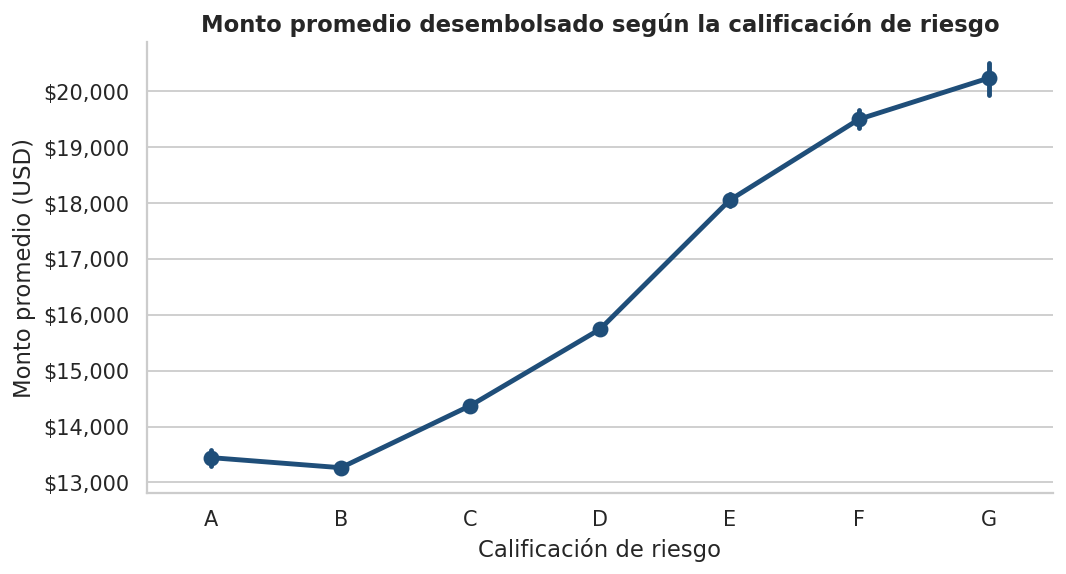

In [54]:
# Monto promedio por calificación
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.pointplot(data=df_modelo, x='calificacion', y='monto', order=orden_calificacion, color='#1f4e79', ax=ax)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
ax.set_title('Monto promedio desembolsado según la calificación de riesgo')
ax.set_xlabel('Calificación de riesgo')
ax.set_ylabel('Monto promedio (USD)')
plt.show()

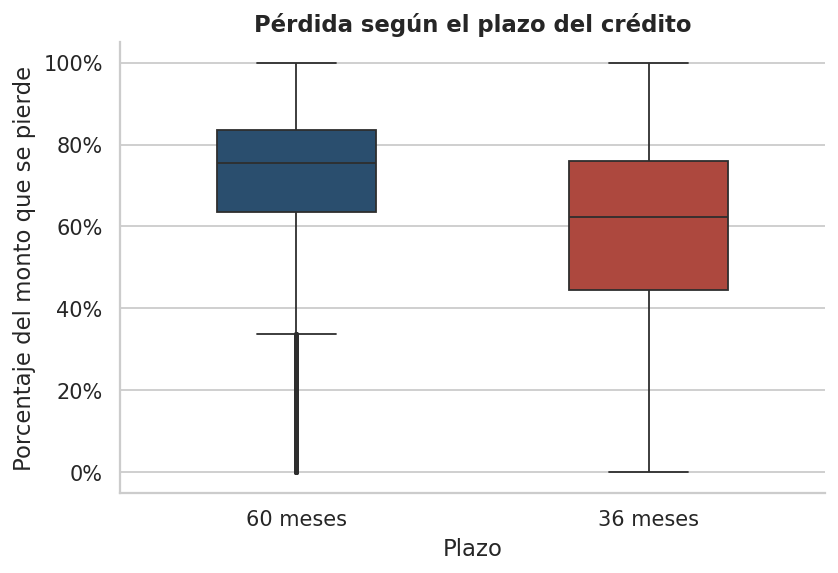

In [55]:
# Pérdida por plazo
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df_modelo, x='plazo', y='lgd', hue='plazo', palette=['#1f4e79', '#c0392b'], legend=False, width=0.45, fliersize=1.5, ax=ax)
ax.yaxis.set_major_formatter(porcentaje)
ax.set_title('Pérdida según el plazo del crédito')
ax.set_xlabel('Plazo')
ax.set_ylabel('Porcentaje del monto que se pierde')
plt.show()

In [56]:
tabla_grupo(df_modelo, 'plazo')

,Créditos,Pérdida promedio (%),Pérdida mediana (%),Desviación (pp),Coef. de variación (%)
plazo,,,,,
36 meses,120341,59.2,62.4,21.6,36.5
60 meses,76062,72.0,75.6,16.4,22.8


In [57]:
# Pérdida por propósito (de mayor a menor pérdida promedio)
tabla_proposito = tabla_grupo(df_modelo, 'proposito').sort_values('Pérdida promedio (%)', ascending=False)
tabla_proposito

,Créditos,Pérdida promedio (%),Pérdida mediana (%),Desviación (pp),Coef. de variación (%)
proposito,,,,,
Energía renovable,173,67.9,70.6,20.5,30.3
Pequeño negocio,3558,66.7,71.6,20.8,31.1
Mudanza,1624,66.6,70.9,20.5,30.8
Compra importante,3829,66.5,71.7,21.5,32.3
Gastos médicos,2369,66.4,71.0,21.0,31.6
Vivienda,1036,66.1,70.6,20.5,31.0
Mejoras del hogar,10946,65.6,70.1,20.7,31.6
Otro,11393,65.3,69.9,21.3,32.7
Consolidación de deudas,121882,64.5,68.7,20.4,31.6


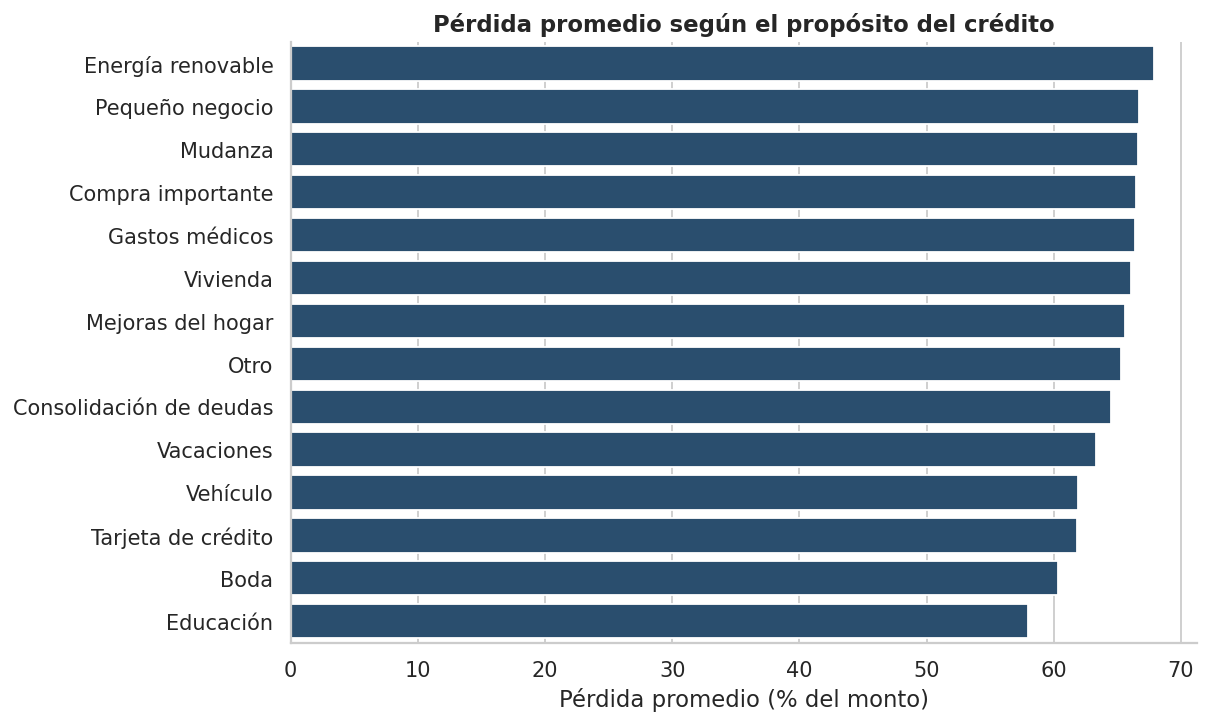

In [58]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=tabla_proposito['Pérdida promedio (%)'], y=tabla_proposito.index, color='#1f4e79', ax=ax)
ax.set_title('Pérdida promedio según el propósito del crédito')
ax.set_xlabel('Pérdida promedio (% del monto)')
ax.set_ylabel('')
plt.show()

#### **Por qué Spearman como medida principal de correlación.**

La correlación de Spearman es la correlación de Pearson calculada sobre los **rangos** de los datos, y mide si dos variables se mueven en la misma dirección (relación monótona), sin exigir que la relación sea una línea recta:

$$\rho_s = 1 - \frac{6\sum_{i=1}^{n} d_i^2}{n(n^2-1)}, \qquad d_i = \text{rango}(x_i) - \text{rango}(y_i)$$

Se usa como medida principal por tres razones:

1. **Las variables no son normales y son muy asimétricas.** El ingreso tiene un coeficiente de variación de 91,8 % y un máximo de 8,9 millones de USD, y la relación deuda/ingreso llega a 999. Pearson supone relaciones lineales y es sensible a la asimetría, mientras que Spearman no depende de la forma de la distribución.
2. **Hay valores extremos.** Como Spearman trabaja con rangos, un valor extremo pesa lo mismo que cualquier otro valor en su posición, y no arrastra el coeficiente.
3. **La LGD está acotada entre 0 y 1** y concentra muchos créditos en valores altos, por lo que la relación con las predictoras puede ser monótona sin ser lineal.

Pearson se calcula a la par para comparar: cuando los dos coinciden, la relación es aproximadamente lineal; cuando difieren, la diferencia la explica la asimetría o los extremos. En estos datos coinciden en monto, tasa y relación deuda/ingreso, y difieren en el ingreso (0,023 con Pearson y 0,050 con Spearman). Al aplicar el logaritmo al ingreso, Pearson sube a 0,050 e iguala a Spearman, lo que confirma que la diferencia venía de la asimetría del ingreso y respalda usar su logaritmo en el modelo.

In [59]:
# Correlaciones: Pearson mide relación LINEAL y es sensible a valores extremos y a la asimetría;
# Spearman mide relación MONÓTONA (usa rangos) y es robusta a ambos. Se calculan las dos:
# si coinciden, la relación es aproximadamente lineal; si Spearman es mayor, hay relación no lineal o efecto de extremos.
variables_corr = ['lgd', 'monto', 'tasa', 'ingreso', 'dti']
nombres_corr = ['Pérdida', 'Monto', 'Tasa', 'Ingreso', 'Deuda/ingreso']
datos_corr = df_ajuste[variables_corr]
pearson = datos_corr.corr(method='pearson')
spearman = datos_corr.corr(method='spearman')

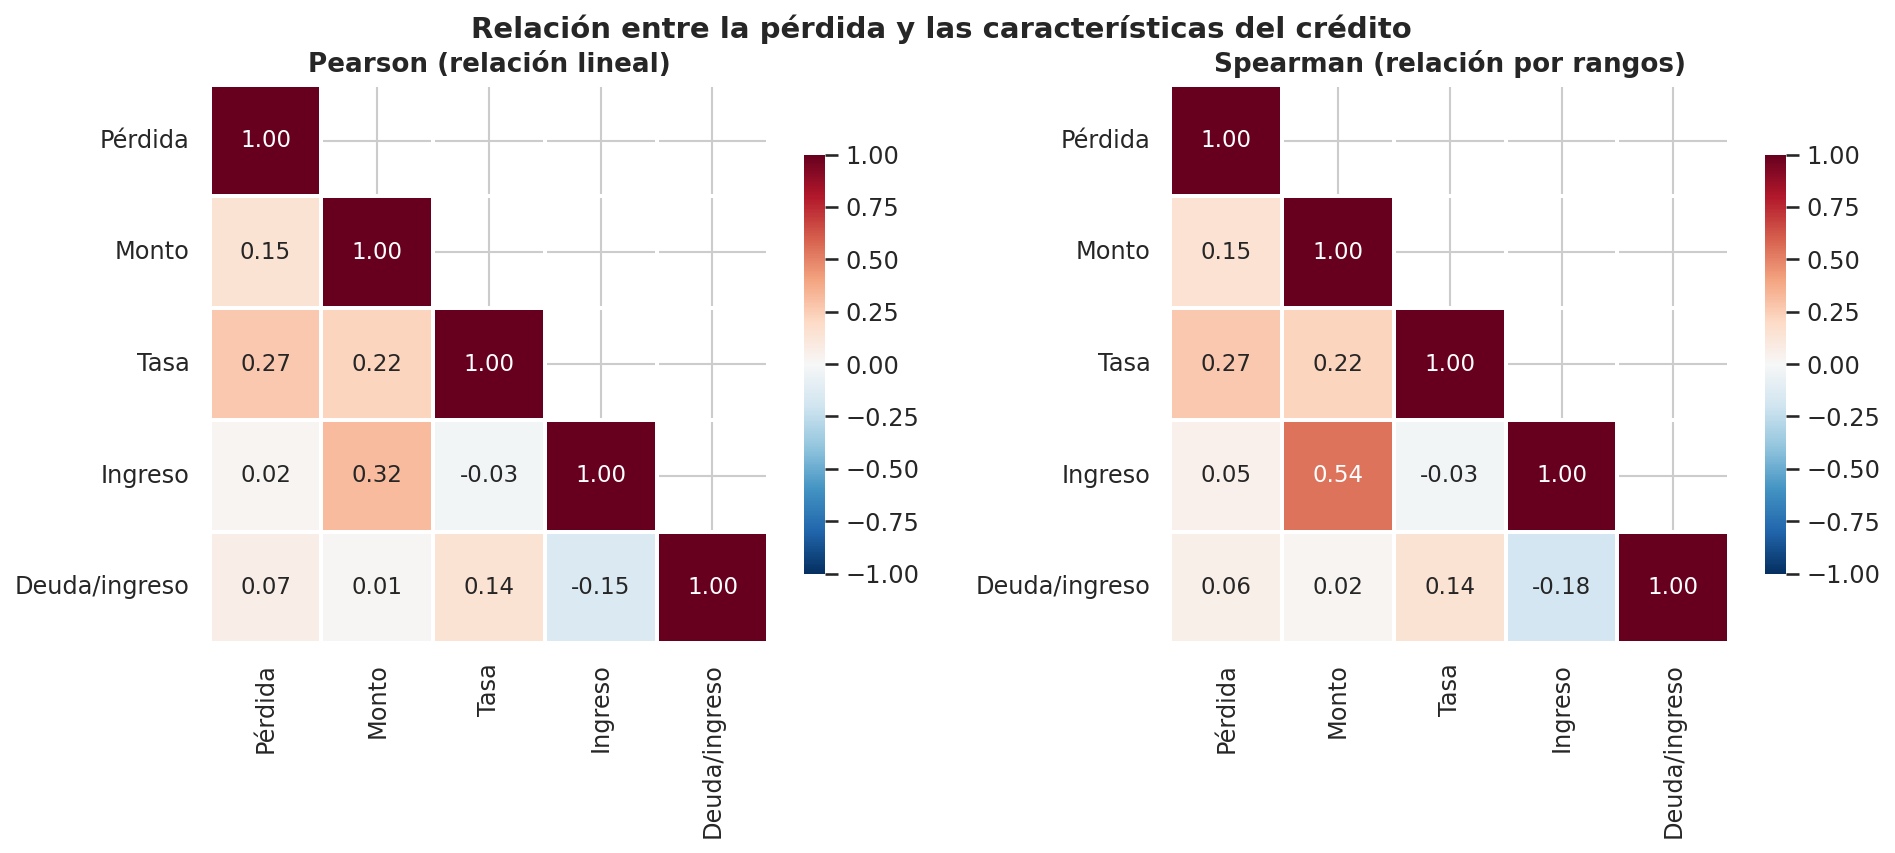

In [60]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)
mascara = np.triu(np.ones_like(pearson, dtype=bool), k=1)
for eje, matriz, titulo in [(ejes[0], pearson, 'Pearson (relación lineal)'), (ejes[1], spearman, 'Spearman (relación por rangos)')]:
    sns.heatmap(matriz, mask=mascara, annot=True, fmt='.2f', annot_kws={'size': 11}, cmap='RdBu_r', vmin=-1, vmax=1,
                square=True, linewidths=1, linecolor='white', cbar_kws={'shrink': 0.75},
                xticklabels=nombres_corr, yticklabels=nombres_corr, ax=eje)
    eje.set_title(titulo)
fig.suptitle('Relación entre la pérdida y las características del crédito', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

In [61]:
# Comparación directa con la pérdida: dónde difieren los dos coeficientes
comparacion_corr = pd.DataFrame({'Pearson': pearson['lgd'], 'Spearman': spearman['lgd']}).drop('lgd')
comparacion_corr['Diferencia'] = comparacion_corr['Spearman'] - comparacion_corr['Pearson']
comparacion_corr.index = nombres_corr[1:]
comparacion_corr.round(3)

,Pearson,Spearman,Diferencia
Monto,0.148,0.152,0.004
Tasa,0.273,0.272,-0.001
Ingreso,0.023,0.050,0.027
Deuda/ingreso,0.068,0.060,-0.008


In [62]:
# El ingreso es muy asimétrico: con su logaritmo, Pearson debería acercarse a Spearman
np.corrcoef(np.log(df_ajuste['ingreso']), df_ajuste['lgd'])[0, 1]

np.float64(0.050129714671060324)

#### **Selección de variables: utilización del crédito.**

La utilización del crédito (`revol_util`, porcentaje del cupo rotativo que usa el prestatario) estaba entre las predictoras del A2-6.1. Antes del modelo se revisa con cifras su relación con la pérdida, con las mismas medidas usadas para las demás variables: faltantes, correlación con la LGD y pérdida promedio por quintiles. Su VIF frente a las demás predictoras se revisa en la sección 3.3, una vez construida la matriz de diseño.

In [ ]:
# Verificación con cifras de la utilización del crédito (revol_util): no estaba entre las 16 columnas cargadas
utilizacion = cargar_base(['id', 'revol_util'])
utilizacion['revol_util'] = pd.to_numeric(utilizacion['revol_util'].astype(str).str.rstrip('%'), errors='coerce')
utilizacion = utilizacion.rename(columns={'id': 'id_prestamo', 'revol_util': 'utilizacion'})
revision_util = df_ajuste.merge(utilizacion, on='id_prestamo', how='left')
print(f"Créditos de df_ajuste: {len(df_ajuste):,} | Con utilización: {revision_util['utilizacion'].notna().sum():,}")

In [64]:
# Faltantes de la utilización
print(f"Faltantes: {revision_util['utilizacion'].isna().sum():,} ({revision_util['utilizacion'].isna().mean() * 100:.2f} %)")
revision_util['utilizacion'].describe().round(2)

Faltantes: 130 (0.07 %)


,utilizacion
count,196234.00
mean,56.00
std,23.61
min,0.00
25%,39.00
50%,57.00
75%,74.20
max,366.60


In [65]:
# Relación con la pérdida, comparada con las demás predictoras numéricas
con_util = revision_util.dropna(subset=['utilizacion']).copy()
pd.DataFrame({
    'Pearson con la pérdida': con_util[['utilizacion', 'monto', 'ingreso', 'dti']].corrwith(con_util['lgd'], method='pearson'),
    'Spearman con la pérdida': con_util[['utilizacion', 'monto', 'ingreso', 'dti']].corrwith(con_util['lgd'], method='spearman'),
}).round(3)

,Pearson con la pérdida,Spearman con la pérdida
utilizacion,-0.021,-0.019
monto,0.148,0.152
ingreso,0.023,0.050
dti,0.068,0.060


In [66]:
# Pérdida promedio por quintil de utilización (de menor a mayor utilización)
con_util['quintil_utilizacion'] = pd.qcut(con_util['utilizacion'], 5, labels=['Q1 (menor)', 'Q2', 'Q3', 'Q4', 'Q5 (mayor)'])
tabla_util = con_util.groupby('quintil_utilizacion', observed=True).agg(creditos=('lgd', 'size'), utilizacion_media=('utilizacion', 'mean'), lgd_media=('lgd', 'mean'))
tabla_util['lgd_media'] = tabla_util['lgd_media'] * 100
tabla_util.round(1)

,creditos,utilizacion_media,lgd_media
quintil_utilizacion,,,
Q1 (menor),39346,21.7,65.5
Q2,39289,42.9,63.8
Q3,39205,57.0,63.6
Q4,39166,70.7,63.7
Q5 (mayor),39228,88.0,64.3


#### **Problema: tasas de interés que no corresponden a su calificación.**

Hay créditos de calificación B a G con una tasa de exactamente 6 %, que es la tasa de los créditos A. **Qué se decide:** se conservan, porque la tasa de interés no entra al modelo (ver el problema de multicolinealidad en la sección 3.3) y no alteran la LGD ni las demás variables.

In [69]:
# Atípico de tasa: 6 % en grados B a G (la tasa no entra al modelo, se conservan)
tasa_6 = df_modelo[(df_modelo['tasa'] == 6.00) & (df_modelo['calificacion'] != 'A')]
tasa_6.groupby(['anio_originacion', 'calificacion']).size()

anio_originacion  calificacion
2013              E               1
2014              B               1
                  C               1
2015              C               2
                  D               2
                  F               1
2016              C               2
                  D               1
                  G               1
2017              F               1
dtype: int64

## **3. Sobre el modelo y Primera especificación de las priors.**

### **3.1. Librerías del pipeline.**

In [70]:
# ===== 3.1 Librerías del pipeline =====
# Pipeline encadena la preparación y el modelo: en cada ajuste, la preparación aprende SOLO de los datos de entrenamiento.
# cross_validate corre la validación cruzada con los pliegues de tiempo que definimos.
# DummyRegressor(strategy='mean') es la línea base: predice la LGD promedio del entrenamiento para todos.
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

### **3.2. Partición temporal: entrenamiento y prueba.**

In [71]:
# ===== 3.2 Partición temporal: entrenamiento y prueba =====
# Entrenamiento (2007-2014): se ajusta el modelo y se hace la validación cruzada.
# Prueba (2015): queda guardada y NO se usa hasta el final (3.10). 2016-2017 no se usan (cohortes incompletas).
columnas_entrada = ['monto', 'ingreso', 'dti', 'calificacion', 'plazo', 'proposito']
entrenamiento = df_ajuste[df_ajuste['anio_originacion'] <= 2014].reset_index(drop=True)
prueba = df_ajuste[df_ajuste['anio_originacion'] == 2015].reset_index(drop=True)
print(f'Entrenamiento (2007-2014): {len(entrenamiento):,} | Prueba (2015): {len(prueba):,}')

Entrenamiento (2007-2014): 75,175 | Prueba (2015): 64,846


In [72]:
x_entrenamiento = entrenamiento[columnas_entrada]
y_entrenamiento = entrenamiento['lgd']

In [73]:
entrenamiento['anio_originacion'].value_counts().sort_index()

,count
anio_originacion,
2007,158
2008,496
2009,723
2010,1757
2011,3297
2012,8641
2013,20746
2014,39357


### **3.3. Preparación de las predictoras.**

#### **Problema: fuga de información entre entrenamiento y prueba.**

Si las medias para centrar las variables o los propósitos que se agrupan se calculan con toda la base, el modelo "ve" información de 2015 antes de evaluarse en 2015. **Qué se decide:** la preparación se programa como un paso del `Pipeline` (`PreparacionLGD`) que aprende todo en `fit()` **solo con los datos de entrenamiento** de cada ajuste, y lo aplica igual en `transform()`. Las dummies se crean a mano dentro de esa clase.

In [74]:
# ===== 3.3 Paso 1 del pipeline: preparación de las predictoras =====
# Todo se aprende en fit() con los datos de entrenamiento y se aplica igual en transform():
#  - Monto en miles de USD, ingreso en log2 (1 unidad = duplicar el ingreso) y dti en puntos, CENTRADOS en su promedio.
#    No se estandarizan (corrección de la profe): así los coeficientes quedan en unidades que se leen directo.
#  - Propósitos con menos del 1 % de los créditos se agrupan en 'Otro' (Avance 2, Paso 3: "se agrupan las pequeñas").
#  - Las dummies se crean a mano, no con un comando: 1 si el crédito es de esa categoría, 0 si no.
#    Referencias (sin columna): calificación A, plazo 36 meses, propósito Consolidación de deudas.
referencias = {'calificacion': 'A', 'plazo': '36 meses', 'proposito': 'Consolidación de deudas'}

class PreparacionLGD(BaseEstimator, TransformerMixin):
    def __init__(self, umbral_proposito=0.01):
        self.umbral_proposito = umbral_proposito

    def _agrupar_proposito(self, proposito):
        return proposito.where(proposito.isin(self.propositos_conservados_), 'Otro')

    def fit(self, X, y=None):
        frecuencia = X['proposito'].value_counts(normalize=True)
        self.propositos_agrupados_ = sorted(frecuencia[frecuencia < self.umbral_proposito].index)
        self.propositos_conservados_ = sorted(set(frecuencia.index) - set(self.propositos_agrupados_))
        self.media_monto_miles_ = (X['monto'] / 1000).mean()
        self.media_log2_ingreso_ = np.log2(X['ingreso']).mean()
        self.media_dti_ = X['dti'].mean()
        datos = X.assign(proposito=self._agrupar_proposito(X['proposito']))
        self.categorias_ = {v: sorted(datos[v].unique()) for v in referencias}
        return self

    def transform(self, X):
        datos = X.assign(proposito=self._agrupar_proposito(X['proposito']))
        salida = pd.DataFrame(index=X.index)
        salida['intercepto'] = 1.0
        salida['monto_miles_c'] = datos['monto'] / 1000 - self.media_monto_miles_
        salida['log2_ingreso_c'] = np.log2(datos['ingreso']) - self.media_log2_ingreso_
        salida['dti_c'] = datos['dti'] - self.media_dti_
        for variable, referencia in referencias.items():
            for categoria in self.categorias_[variable]:
                if categoria != referencia:
                    salida[f'{variable}_{categoria}'] = (datos[variable] == categoria).astype(float)
        return salida

In [75]:
# Revisión de la preparación con todo el entrenamiento (transparencia: así queda la X que recibe el modelo)
preparacion = PreparacionLGD().fit(x_entrenamiento)
x_preparada = preparacion.transform(x_entrenamiento)
print('Propósitos agrupados en Otro:', preparacion.propositos_agrupados_)
x_preparada.head()

Propósitos agrupados en Otro: ['Boda', 'Educación', 'Energía renovable', 'Mudanza', 'Vacaciones', 'Vehículo', 'Vivienda']


,intercepto,monto_miles_c,log2_ingreso_c,dti_c,calificacion_B,calificacion_C,calificacion_D,calificacion_E,calificacion_F,calificacion_G,plazo_60 meses,proposito_Compra importante,proposito_Gastos médicos,proposito_Mejoras del hogar,proposito_Otro,proposito_Pequeño negocio,proposito_Tarjeta de crédito
0,1.0,-4.648758,-0.005979,-3.74647,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.0,-7.398758,-0.220103,16.14353,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,8.276242,0.305965,8.36353,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,-2.073758,0.042931,3.75353,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,-5.048758,0.627894,-10.22647,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [76]:
# Las numéricas quedan con promedio 0; las dummies muestran la proporción de cada categoría
x_preparada.mean().round(3)

,0
intercepto,1.000
monto_miles_c,-0.000
log2_ingreso_c,-0.000
dti_c,0.000
calificacion_B,0.200
calificacion_C,0.292
calificacion_D,0.236
calificacion_E,0.140
calificacion_F,0.060
calificacion_G,0.017


#### **Problema de multicolinealidad.**

**Qué es.** Hay multicolinealidad cuando dos o más predictoras repiten casi la misma información. En la regresión, el modelo no puede separar el efecto de cada una: los coeficientes se vuelven inestables, sus intervalos de credibilidad se ensanchan y su interpretación pierde sentido (por ejemplo, el efecto de la calificación "se reparte" con el de la tasa).

**Cómo se mide.** Con el factor de inflación de la varianza de cada predictora $j$:

$$VIF_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es qué parte de la predictora $j$ explican todas las demás. $VIF < 5$: sin problema; entre 5 y 10: multicolinealidad alta; $> 10$: severa. Con todas las predictoras a la vez, los VIF son la diagonal de la inversa de su matriz de correlación.

**Qué se encontró y qué se decidió.**

| Revisión | Resultado | Decisión |
|---|---|---|
| Tasa de interés frente a calificación | Correlación de Spearman de 0,952; la calificación explica el 89,7 % de la tasa (VIF de 9,7); sus rangos por calificación casi no se solapan | Se **excluye la tasa**: LendingClub la fija a partir de la calificación, y la calificación es la variable de la pregunta de investigación |
| Predictoras finales del modelo | VIF máximo de 4,60 (dummy de calificación C); monto 1,90, ingreso 1,57, plazo 1,52, relación deuda/ingreso 1,10 | Sin multicolinealidad: se conservan todas |
| Pares de predictoras más relacionados | La correlación más alta es 0,56 (monto e ingreso) | Relación moderada y esperable |
| Utilización del crédito, si se agregara | VIF de 1,14 | No se excluyó por multicolinealidad sino por su relación casi nula con la pérdida (sección 2) |

Las dummies de calificación tienen los VIF más altos porque pertenecen a un mismo grupo (un crédito solo puede tener una calificación), lo cual es normal y no llega a 5. En la sección 3.12 se verifica, como análisis exploratorio, que la parte de la tasa que la calificación no explica tampoco mejora el modelo.

In [67]:
# Multicolinealidad tasa-calificación: VIF = 1 / (1 - R²) de la tasa explicada por la calificación
dummies_calificacion = pd.get_dummies(df_ajuste['calificacion'], drop_first=True, dtype=float)
x_vif = np.column_stack([np.ones(len(df_ajuste)), dummies_calificacion.values])
beta_vif, *_ = np.linalg.lstsq(x_vif, df_ajuste['tasa'].values, rcond=None)
residuo_vif = df_ajuste['tasa'].values - x_vif @ beta_vif
r2_vif = 1 - (residuo_vif ** 2).sum() / ((df_ajuste['tasa'] - df_ajuste['tasa'].mean()) ** 2).sum()
print(f'R² = {r2_vif:.3f} | VIF = {1 / (1 - r2_vif):.1f}')

R² = 0.897 | VIF = 9.7


In [68]:
# Tasa de interés por calificación: los rangos casi no se solapan
df_ajuste.groupby('calificacion')['tasa'].describe()[['count', 'mean', 'min', '25%', '75%', 'max']].round(2)

,count,mean,min,25%,75%,max
calificacion,,,,,,
A,10096.0,7.46,5.32,6.92,7.90,9.63
B,37300.0,10.89,6.00,9.99,11.53,14.09
C,60223.0,14.05,6.00,12.99,14.98,17.27
D,45096.0,17.53,6.00,16.55,18.25,21.49
E,28331.0,20.70,6.00,19.19,21.98,26.30
F,11796.0,24.51,6.00,23.13,25.57,30.75
G,3522.0,27.09,6.00,25.83,28.67,30.99


In [77]:
# Multicolinealidad entre las predictoras que SÍ entran al modelo: VIF de cada columna de X (sin el intercepto)
# VIF = 1 / (1 - R²) de cada columna explicada por todas las demás; equivale a la diagonal de la inversa de la matriz de correlación
x_sin_intercepto = x_preparada.drop(columns='intercepto')
vif_final = pd.Series(np.diag(np.linalg.inv(x_sin_intercepto.corr().to_numpy())), index=x_sin_intercepto.columns, name='VIF')
vif_final.sort_values(ascending=False).round(2)

,VIF
calificacion_C,4.60
calificacion_D,4.28
calificacion_B,3.71
calificacion_E,3.41
calificacion_F,2.19
monto_miles_c,1.90
log2_ingreso_c,1.57
plazo_60 meses,1.52
calificacion_G,1.37
proposito_Otro,1.12


In [78]:
# Correlaciones más fuertes entre pares de predictoras (en valor absoluto)
correlaciones = x_sin_intercepto.corr().where(np.triu(np.ones((x_sin_intercepto.shape[1],) * 2, dtype=bool), k=1)).stack()
correlaciones.abs().sort_values(ascending=False).head(10).round(3)

monto_miles_c   log2_ingreso_c    0.559
                plazo_60 meses    0.465
calificacion_C  calificacion_D    0.356
calificacion_B  calificacion_C    0.321
                calificacion_D    0.278
                plazo_60 meses    0.269
calificacion_C  calificacion_E    0.259
calificacion_E  plazo_60 meses    0.242
calificacion_D  calificacion_E    0.224
log2_ingreso_c  plazo_60 meses    0.209
dtype: float64

In [79]:
# VIF si se agregara la utilización del crédito a las predictoras (solo entrenamiento): complementa la revisión del EDA
entrenamiento_util = con_util[con_util['anio_originacion'] <= 2014]
x_util = preparacion.transform(entrenamiento_util[columnas_entrada]).drop(columns='intercepto')
x_util['utilizacion_c'] = entrenamiento_util['utilizacion'] - entrenamiento_util['utilizacion'].mean()
vif_util = pd.Series(np.diag(np.linalg.inv(x_util.corr().to_numpy())), index=x_util.columns, name='VIF')
print(f"VIF de la utilización del crédito: {vif_util['utilizacion_c']:.2f}")
vif_util.sort_values(ascending=False).round(2).head(8)

VIF de la utilización del crédito: 1.14


,VIF
calificacion_C,4.75
calificacion_D,4.47
calificacion_B,3.75
calificacion_E,3.57
calificacion_F,2.28
monto_miles_c,1.90
log2_ingreso_c,1.59
plazo_60 meses,1.53


In [80]:
nombres = list(x_preparada.columns)
print(f'{len(nombres)} coeficientes: {nombres}')

17 coeficientes: ['intercepto', 'monto_miles_c', 'log2_ingreso_c', 'dti_c', 'calificacion_B', 'calificacion_C', 'calificacion_D', 'calificacion_E', 'calificacion_F', 'calificacion_G', 'plazo_60 meses', 'proposito_Compra importante', 'proposito_Gastos médicos', 'proposito_Mejoras del hogar', 'proposito_Otro', 'proposito_Pequeño negocio', 'proposito_Tarjeta de crédito']


### **3.4. Especificación de las priors.**

In [81]:
# ===== 3.4 Especificación de las priors =====
# Modelo semiconjugado:  β ~ Normal(β0, Σ0) con Σ0 diagonal   y   σ² ~ Gamma-Inversa(ν0/2, ν0·σ0²/2)
# Cada grupo de coeficientes: (media a priori, desviación a priori). Argumentos:
#  - intercepto: LGD de un crédito de referencia (A, 36 meses, consolidación, características promedio).
#    Media 0,45: LGD de supervisión para créditos sin garantía del enfoque básico de Basilea (BCBS, 2022).
#    Desviación 0,15: el 95 % del prior queda entre 16 % y 74 %, amplio a propósito.
#  - calificación (B a G frente a A): media 0, no se impone que la pérdida suba con el riesgo (es lo que se quiere probar).
#    Desviación 0,20: admite diferencias de hasta ±39 pp frente a A.
#  - plazo de 60 meses y propósitos: media 0, desviación 0,10 (diferencias de hasta ±20 pp).
#  - monto (por cada 1.000 USD): media 0, desviación 0,01 (hasta ±2 pp por cada 1.000 USD).
#  - ingreso (por duplicarlo): media 0, desviación 0,05 (hasta ±10 pp).
#  - dti (por cada punto): media 0, desviación 0,005 (hasta ±10 pp por cada 10 puntos).
prior_grupos = {
    'intercepto': (0.45, 0.15),
    'monto_miles_c': (0.0, 0.01),
    'log2_ingreso_c': (0.0, 0.05),
    'dti_c': (0.0, 0.005),
    'calificacion_': (0.0, 0.20),
    'plazo_': (0.0, 0.10),
    'proposito_': (0.0, 0.10),
}

In [82]:
# σ² (varianza del error): una variable uniforme en [0,1] tiene desviación 0,29, casi la máxima dispersión razonable para la LGD.
# Se centra el prior en σ0 = 0,25 con ν0 = 5 (información equivalente a solo 5 créditos: prior débil).
nu0 = 5
s02 = 0.25 ** 2

In [83]:
# Vectores de medias y desviaciones a priori, en el mismo orden que las columnas de X
def vectores_prior(nombres_columnas, grupos):
    medias, desviaciones = [], []
    for nombre in nombres_columnas:
        grupo = next(g for g in grupos if nombre == g or nombre.startswith(g))
        medias.append(grupos[grupo][0])
        desviaciones.append(grupos[grupo][1])
    return np.array(medias), np.array(desviaciones)

beta0, sd_prior = vectores_prior(nombres, prior_grupos)

In [84]:
# Tabla de priors para el informe
tabla_priors = pd.DataFrame({'Distribución': 'Normal', 'Media a priori': beta0, 'Desviación a priori': sd_prior,
                             'Límite inferior 95 %': beta0 - 1.96 * sd_prior, 'Límite superior 95 %': beta0 + 1.96 * sd_prior},
                            index=nombres)
tabla_priors.round(3)

,Distribución,Media a priori,Desviación a priori,Límite inferior 95 %,Límite superior 95 %
intercepto,Normal,0.45,0.150,0.156,0.744
monto_miles_c,Normal,0.00,0.010,-0.020,0.020
log2_ingreso_c,Normal,0.00,0.050,-0.098,0.098
dti_c,Normal,0.00,0.005,-0.010,0.010
calificacion_B,Normal,0.00,0.200,-0.392,0.392
calificacion_C,Normal,0.00,0.200,-0.392,0.392
calificacion_D,Normal,0.00,0.200,-0.392,0.392
calificacion_E,Normal,0.00,0.200,-0.392,0.392
calificacion_F,Normal,0.00,0.200,-0.392,0.392
calificacion_G,Normal,0.00,0.200,-0.392,0.392


In [85]:
# Prior de σ²: Gamma-Inversa(a, b), reportado como σ (desviación) para leerlo mejor
a0, b0 = nu0 / 2, nu0 * s02 / 2
prior_sigma2 = stats.invgamma(a0, scale=b0)
print(f'σ² ~ Gamma-Inversa({a0}, {b0:.4f}) | E[σ²] = {nu0 * s02 / (nu0 - 2):.4f}')
print('σ a priori, percentiles 5 / 50 / 95:', np.sqrt(prior_sigma2.ppf([0.05, 0.5, 0.95])).round(3))

σ² ~ Gamma-Inversa(2.5, 0.1562) | E[σ²] = 0.1042
σ a priori, percentiles 5 / 50 / 95: [0.168 0.268 0.522]


In [86]:
# Resumen de las priors con el argumento detrás de cada una
argumentos = {
    'intercepto': ('Pérdida de un crédito de referencia: calificación A, 36 meses, consolidación de deudas y monto, ingreso y dti promedio',
                   'Se centra en 45 %, la pérdida de supervisión que Basilea asigna a créditos sin garantía (BCBS, 2022). La desviación de 0,15 deja el 95 % entre 16 % y 74 %, amplio a propósito porque LendingClub no tiene garantías y su pérdida puede ser mayor.'),
    'monto_miles_c': ('Cambio en la pérdida por cada 1.000 USD más de monto',
                      'Media 0: no se supone de antemano si un monto mayor pierde más o menos. Con desviación 0,01, 10.000 USD más cambiarían la pérdida como mucho ±20 pp, un rango amplio pero realista.'),
    'log2_ingreso_c': ('Cambio en la pérdida cuando el ingreso se duplica',
                       'Media 0: el EDA no muestra una relación clara entre ingreso y pérdida. La desviación de 0,05 permite hasta ±10 pp por duplicar el ingreso.'),
    'dti_c': ('Cambio en la pérdida por cada punto más de deuda frente al ingreso',
              'Media 0, sin dirección supuesta. Con desviación 0,005, 10 puntos más de dti cambiarían la pérdida como mucho ±10 pp.'),
    'calificacion_': ('Pérdida adicional de cada calificación (B a G) frente a A',
                      'Media 0: no se impone que la pérdida suba con el riesgo, porque eso es justamente lo que se quiere comprobar. La desviación de 0,20 admite diferencias de hasta ±39 pp, más que la diferencia de 23,6 pp entre G y A que muestra el fenómeno, así que el prior no limita el resultado.'),
    'plazo_': ('Pérdida adicional de los créditos a 60 meses frente a 36 meses',
               'Media 0 y desviación 0,10: admite diferencias de hasta ±20 pp sin suponer cuál plazo pierde más.'),
    'proposito_': ('Pérdida adicional de cada propósito frente a consolidación de deudas',
                   'Media 0 y desviación 0,10: se espera que las diferencias entre propósitos sean menores que entre calificaciones; se permiten hasta ±20 pp.'),
}
filas_prior = []
for grupo, (media, sd) in prior_grupos.items():
    coeficientes = [n for n in nombres if n == grupo or n.startswith(grupo)]
    filas_prior.append({'Parámetro': grupo.rstrip('_').replace('_c', ''), 'Qué representa': argumentos[grupo][0],
                        'Coeficientes': len(coeficientes), 'Distribución': 'Normal',
                        'Hiperparámetros': f'media = {media}, desviación = {sd}',
                        'Intervalo 95 % a priori': f'[{media - 1.96 * sd:.3f}; {media + 1.96 * sd:.3f}]',
                        'Argumento': argumentos[grupo][1]})
filas_prior.append({'Parámetro': 'sigma²', 'Qué representa': 'Varianza del error: cuánto se alejan las pérdidas reales de lo que predice el modelo',
                    'Coeficientes': 1, 'Distribución': 'Gamma-Inversa',
                    'Hiperparámetros': f'ν0 = {nu0}, σ0 = {np.sqrt(s02):.2f}  ->  IG({nu0 / 2}, {nu0 * s02 / 2:.4f})',
                    'Intervalo 95 % a priori': f'σ entre {np.sqrt(prior_sigma2.ppf(0.025)):.3f} y {np.sqrt(prior_sigma2.ppf(0.975)):.3f}',
                    'Argumento': 'Es la prior conjugada de la varianza en la regresión normal, lo que permite el muestreo de Gibbs. Una pérdida uniforme entre 0 y 1 tendría desviación 0,29, casi la máxima posible, por eso se centra en σ0 = 0,25. ν0 = 5 equivale a la información de solo 5 créditos: es un prior débil frente a decenas de miles de datos.'})
resumen_priors = pd.DataFrame(filas_prior).set_index('Parámetro')
with pd.option_context('display.max_colwidth', None):
    display(resumen_priors.style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'}))

,Qué representa,Coeficientes,Distribución,Hiperparámetros,Intervalo 95 % a priori,Argumento
Parámetro,,,,,,
intercepto,"Pérdida de un crédito de referencia: calificación A, 36 meses, consolidación de deudas y monto, ingreso y dti promedio",1,Normal,"media = 0.45, desviación = 0.15",[0.156; 0.744],"Se centra en 45 %, la pérdida de supervisión que Basilea asigna a créditos sin garantía (BCBS, 2022). La desviación de 0,15 deja el 95 % entre 16 % y 74 %, amplio a propósito porque LendingClub no tiene garantías y su pérdida puede ser mayor."
monto_miles,Cambio en la pérdida por cada 1.000 USD más de monto,1,Normal,"media = 0.0, desviación = 0.01",[-0.020; 0.020],"Media 0: no se supone de antemano si un monto mayor pierde más o menos. Con desviación 0,01, 10.000 USD más cambiarían la pérdida como mucho ±20 pp, un rango amplio pero realista."
log2_ingreso,Cambio en la pérdida cuando el ingreso se duplica,1,Normal,"media = 0.0, desviación = 0.05",[-0.098; 0.098],"Media 0: el EDA no muestra una relación clara entre ingreso y pérdida. La desviación de 0,05 permite hasta ±10 pp por duplicar el ingreso."
dti,Cambio en la pérdida por cada punto más de deuda frente al ingreso,1,Normal,"media = 0.0, desviación = 0.005",[-0.010; 0.010],"Media 0, sin dirección supuesta. Con desviación 0,005, 10 puntos más de dti cambiarían la pérdida como mucho ±10 pp."
calificacion,Pérdida adicional de cada calificación (B a G) frente a A,6,Normal,"media = 0.0, desviación = 0.2",[-0.392; 0.392],"Media 0: no se impone que la pérdida suba con el riesgo, porque eso es justamente lo que se quiere comprobar. La desviación de 0,20 admite diferencias de hasta ±39 pp, más que la diferencia de 23,6 pp entre G y A que muestra el fenómeno, así que el prior no limita el resultado."
plazo,Pérdida adicional de los créditos a 60 meses frente a 36 meses,1,Normal,"media = 0.0, desviación = 0.1",[-0.196; 0.196],"Media 0 y desviación 0,10: admite diferencias de hasta ±20 pp sin suponer cuál plazo pierde más."
proposito,Pérdida adicional de cada propósito frente a consolidación de deudas,6,Normal,"media = 0.0, desviación = 0.1",[-0.196; 0.196],"Media 0 y desviación 0,10: se espera que las diferencias entre propósitos sean menores que entre calificaciones; se permiten hasta ±20 pp."
sigma²,Varianza del error: cuánto se alejan las pérdidas reales de lo que predice el modelo,1,Gamma-Inversa,"ν0 = 5, σ0 = 0.25 -> IG(2.5, 0.1562)",σ entre 0.156 y 0.613,"Es la prior conjugada de la varianza en la regresión normal, lo que permite el muestreo de Gibbs. Una pérdida uniforme entre 0 y 1 tendría desviación 0,29, casi la máxima posible, por eso se centra en σ0 = 0,25. ν0 = 5 equivale a la información de solo 5 créditos: es un prior débil frente a decenas de miles de datos."


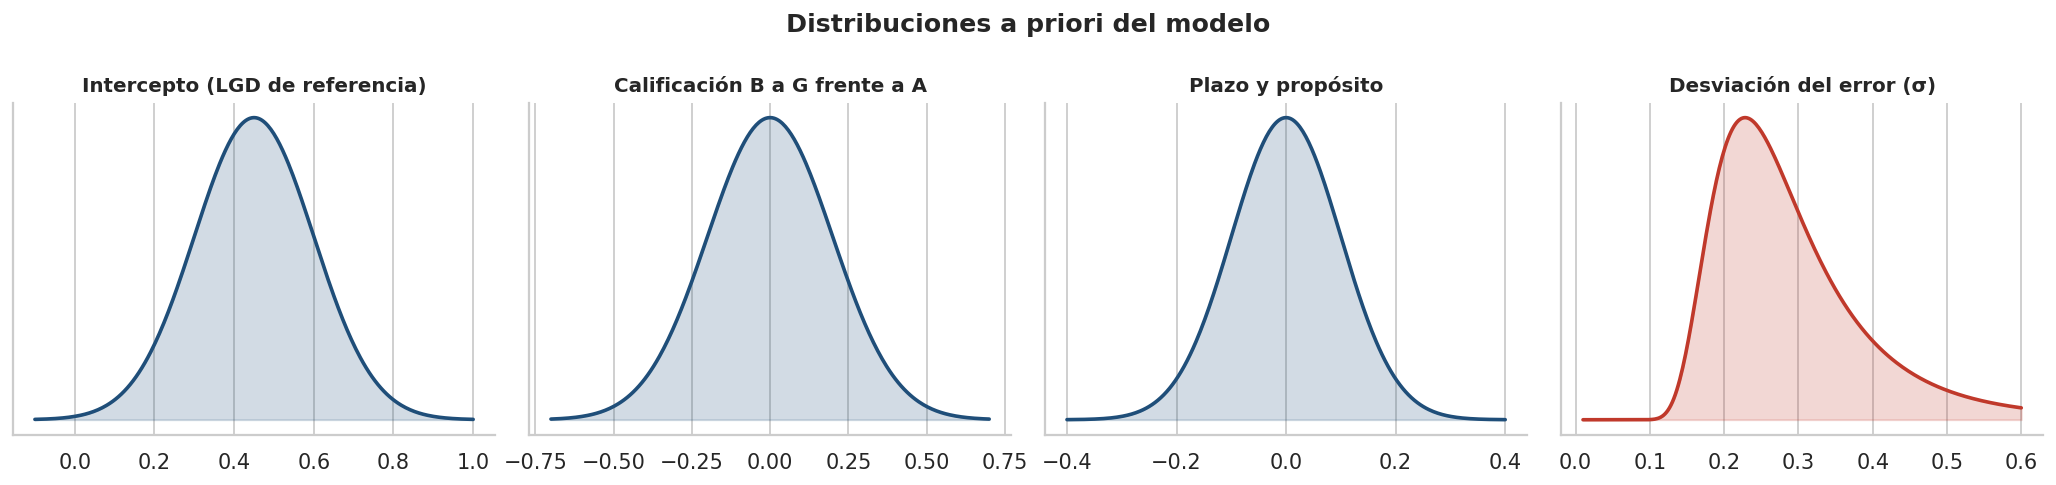

In [87]:
# Gráfico de las priors
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.8))
for eje, (titulo, media, sd, xs) in zip(ejes[:3], [
        ('Intercepto (LGD de referencia)', 0.45, 0.15, np.linspace(-0.1, 1.0, 300)),
        ('Calificación B a G frente a A', 0.0, 0.20, np.linspace(-0.7, 0.7, 300)),
        ('Plazo y propósito', 0.0, 0.10, np.linspace(-0.4, 0.4, 300))]):
    eje.plot(xs, stats.norm(media, sd).pdf(xs), color='#1f4e79', linewidth=2)
    eje.fill_between(xs, stats.norm(media, sd).pdf(xs), alpha=0.2, color='#1f4e79')
    eje.set_title(titulo, fontsize=11)
    eje.set_yticks([])
xs = np.linspace(0.01, 0.6, 300)
densidad_sigma = prior_sigma2.pdf(xs ** 2) * 2 * xs        # cambio de variable de σ² a σ
ejes[3].plot(xs, densidad_sigma, color='#c0392b', linewidth=2)
ejes[3].fill_between(xs, densidad_sigma, alpha=0.2, color='#c0392b')
ejes[3].set_title('Desviación del error (σ)', fontsize=11)
ejes[3].set_yticks([])
fig.suptitle('Distribuciones a priori del modelo', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

In [88]:
# Chequeo predictivo a priori: ¿qué LGD generan las priors ANTES de ver la LGD observada?
filas = rng.choice(len(x_preparada), size=2000, replace=False)
beta_sim = rng.normal(beta0, sd_prior, size=(2000, len(beta0)))
sigma2_sim = prior_sigma2.rvs(size=2000, random_state=semilla)
y_sim = beta_sim @ x_preparada.to_numpy()[filas].T + rng.standard_normal((2000, len(filas))) * np.sqrt(sigma2_sim)[:, None]
print(f'Percentiles 2,5 / 50 / 97,5 de la LGD simulada: {np.percentile(y_sim, [2.5, 50, 97.5]).round(2)}')
print(f'% de LGD simuladas fuera de [0, 1]: {((y_sim < 0) | (y_sim > 1)).mean() * 100:.1f} %')

Percentiles 2,5 / 50 / 97,5 de la LGD simulada: [-0.39  0.45  1.3 ]
% de LGD simuladas fuera de [0, 1]: 22.6 %


### **3.5. Likelihood y muestreador de Gibbs.**

#### **Especificación completa del modelo bayesiano.**

**1. Datos y notación.** $y_i = LGD_i$ para los $n = 75.175$ créditos de entrenamiento (2007–2014). $x_i$ es el vector de 17 predictoras del crédito $i$: intercepto, monto (miles de USD, centrado), ingreso (log2, centrado), relación deuda/ingreso (puntos, centrada), 6 dummies de calificación (B a G frente a A), 1 de plazo (60 frente a 36 meses) y 6 de propósito (frente a consolidación de deudas). $X$ es la matriz $n \times 17$ que junta todos los $x_i$.

**2. Likelihood (verosimilitud).** Cada LGD se modela como Normal alrededor de una combinación lineal de las predictoras, independiente entre créditos:

$$y_i \mid \beta, \sigma^2 \sim \text{Normal}\left(x_i^\top\beta,\ \sigma^2\right) \qquad\Rightarrow\qquad p(y \mid \beta, \sigma^2) = \prod_{i=1}^{n} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left\{-\frac{(y_i - x_i^\top\beta)^2}{2\sigma^2}\right\}$$

**3. Priors.** Independientes entre $\beta$ y $\sigma^2$, y entre cada coeficiente:

$$\beta_j \sim \text{Normal}\left(\beta_{0j},\ \tau_j^2\right),\ j = 1, \dots, 17 \qquad\qquad \sigma^2 \sim \text{Gamma-Inversa}\left(a_0 = \tfrac{\nu_0}{2},\ b_0 = \tfrac{\nu_0\sigma_0^2}{2}\right)$$

| Parámetro | Distribución | Media a priori | Desviación a priori | Intervalo del 95 % a priori |
|---|---|---|---|---|
| Intercepto (LGD de un crédito A, 36 meses, consolidación, características promedio) | Normal | 0,45 | 0,15 | [0,16; 0,74] |
| Monto (por cada 1.000 USD) | Normal | 0 | 0,01 | [−0,02; 0,02] |
| Ingreso (por duplicarlo) | Normal | 0 | 0,05 | [−0,10; 0,10] |
| Relación deuda/ingreso (por punto) | Normal | 0 | 0,005 | [−0,01; 0,01] |
| Calificación B a G (frente a A) | Normal | 0 | 0,20 | [−0,39; 0,39] |
| Plazo 60 meses (frente a 36) | Normal | 0 | 0,10 | [−0,20; 0,20] |
| Propósitos (frente a consolidación) | Normal | 0 | 0,10 | [−0,20; 0,20] |
| $\sigma^2$ (varianza del error) | Gamma-Inversa | $\nu_0 = 5$, $\sigma_0 = 0{,}25$: $\text{GI}(2{,}5;\ 0{,}156)$ | | $\sigma$ entre 0,15 y 0,62 |

**4. Posterior (teorema de Bayes).**

$$p(\beta, \sigma^2 \mid y) \ \propto\ \underbrace{p(y \mid \beta, \sigma^2)}_{\text{likelihood}}\ \times\ \underbrace{p(\beta)}_{\text{prior Normal}}\ \times\ \underbrace{p(\sigma^2)}_{\text{prior Gamma-Inversa}}$$

Esta posterior conjunta no tiene una forma conocida, por eso no se puede calcular directamente.

**5. Por qué las priors son semiconjugadas.** *Conjugada* significa que la prior y la posterior son de la misma familia. Aquí ocurre por partes: si se conoce $\sigma^2$, la prior Normal de $\beta$ con la likelihood Normal da una posterior **Normal**; si se conoce $\beta$, la prior Gamma-Inversa de $\sigma^2$ con la likelihood Normal da una posterior **Gamma-Inversa**. Cada condicional tiene forma conocida, aunque la conjunta no, y eso es lo que permite usar Gibbs. Se eligen semiconjugadas (y no totalmente conjugadas) para que la prior de cada coeficiente se fije directamente en puntos porcentuales de LGD, sin depender de $\sigma^2$.

**6. Condicionales completas.** Con $\Sigma_0 = \text{diag}(\tau_1^2, \dots, \tau_{17}^2)$:

$$\beta \mid \sigma^2, y \ \sim\ \text{Normal}\left(m_n,\ V_n\right), \qquad V_n = \left(\Sigma_0^{-1} + \frac{1}{\sigma^2}X^\top X\right)^{-1}, \qquad m_n = V_n\left(\Sigma_0^{-1}\beta_0 + \frac{1}{\sigma^2}X^\top y\right)$$

$$\sigma^2 \mid \beta, y \ \sim\ \text{Gamma-Inversa}\left(\frac{\nu_0 + n}{2},\ \frac{\nu_0\sigma_0^2 + SCR(\beta)}{2}\right), \qquad SCR(\beta) = \sum_{i=1}^{n}\left(y_i - x_i^\top\beta\right)^2$$

$m_n$ es un promedio ponderado entre lo que dice la prior ($\beta_0$, con peso $\Sigma_0^{-1}$) y lo que dicen los datos (con peso $X^\top X / \sigma^2$). Con 75.175 créditos, los datos dominan.

**7. Algoritmo de Gibbs** (función `gibbs`, sección 3.5):
1. Calcular una sola vez $X^\top X$, $X^\top y$ e $y^\top y$.
2. Iniciar cada cadena en un punto distinto sacado de las priors: $\beta^{(0)} \sim N(\beta_0, \Sigma_0)$ y $\sigma^{2(0)} \sim \text{GI}(a_0, b_0)$.
3. Para $t = 1, \dots, 6.000$:
   - sacar $\beta^{(t)} \sim N(m_n, V_n)$ usando $\sigma^{2(t-1)}$;
   - sacar $\sigma^{2(t)} \sim \text{GI}\left(\frac{\nu_0+n}{2}, \frac{\nu_0\sigma_0^2 + SCR(\beta^{(t)})}{2}\right)$ usando $\beta^{(t)}$.
4. Quemar las primeras 1.000 iteraciones de cada cadena (calentamiento, antes de llegar a la posterior).
5. Repetir con 4 cadenas: quedan $4 \times 5.000 = 20.000$ muestras de $p(\beta, \sigma^2 \mid y)$.

**8. Cómo se usa la posterior.**
- **Predicción:** $\widehat{LGD}_i = x_i^\top\bar\beta$, con $\bar\beta$ la media de las 20.000 muestras.
- **Intervalos de credibilidad del 95 %:** percentiles 2,5 y 97,5 de las muestras.
- **Probabilidades posteriores:** proporción de muestras que cumplen una condición, por ejemplo $P(\beta_G > 0 \mid y)$.
- **Convergencia:** $\hat R < 1{,}01$, tamaño efectivo de muestra, trazas, autocorrelación y media acumulada (sección 3.9).

In [89]:
# ===== 3.5 Likelihood y muestreador de Gibbs =====
# Likelihood: y_i | β, σ² ~ Normal(x_i·β, σ²), independientes.
# Condicionales completas (derivación en el apéndice matemático):
#   β | σ², y  ~ Normal(m_n, V_n),  V_n = (Σ0⁻¹ + XᵀX/σ²)⁻¹,  m_n = V_n (Σ0⁻¹β0 + Xᵀy/σ²)
#   σ² | β, y  ~ Gamma-Inversa((ν0 + n)/2, (ν0·σ0² + SCR)/2),  SCR = Σ (y_i - x_i·β)²
# XᵀX, Xᵀy y yᵀy se calculan una sola vez, así cada iteración no recorre los n créditos.
def gibbs(x, y, beta0, sd_prior, nu0, s02, n_iter, semilla_cadena, beta_inicial, sigma2_inicial):
    generador = np.random.default_rng(semilla_cadena)
    n, p = x.shape
    xtx, xty, yty = x.T @ x, x.T @ y, y @ y
    precision0 = np.diag(1 / sd_prior ** 2)
    precision0_beta0 = precision0 @ beta0
    beta, sigma2 = beta_inicial.copy(), sigma2_inicial
    muestras_beta = np.empty((n_iter, p))
    muestras_sigma2 = np.empty(n_iter)
    for t in range(n_iter):
        # Paso 1: β dado σ²
        v_n = np.linalg.inv(precision0 + xtx / sigma2)
        m_n = v_n @ (precision0_beta0 + xty / sigma2)
        beta = m_n + np.linalg.cholesky(v_n) @ generador.standard_normal(p)
        # Paso 2: σ² dado β
        scr = yty - 2 * beta @ xty + beta @ xtx @ beta
        sigma2 = 1 / generador.gamma((nu0 + n) / 2, 1 / ((nu0 * s02 + scr) / 2))
        muestras_beta[t] = beta
        muestras_sigma2[t] = sigma2
    return muestras_beta, muestras_sigma2

### **3.6. Modelo de regresión bayesiana dentro del pipeline.**

In [90]:
# ===== 3.6 Paso 2 del pipeline: el modelo bayesiano =====
# Envuelve el Gibbs para que funcione dentro del Pipeline. En fit():
#  - corre n_cadenas cadenas, cada una arranca en un punto distinto sacado de las priors;
#  - QUEMA las primeras 'calentamiento' iteraciones de cada cadena (antes de llegar a la posterior pueden dar valores extraños);
#  - con lo que queda calcula la media posterior de cada coeficiente, que es la que usa predict().
class RegresionBayesianaGibbs(BaseEstimator, RegressorMixin):
    def __init__(self, prior_grupos=None, nu0=5, s02=0.0625, n_cadenas=4, n_iter=6000, calentamiento=1000, semilla=2026):
        self.prior_grupos = prior_grupos
        self.nu0 = nu0
        self.s02 = s02
        self.n_cadenas = n_cadenas
        self.n_iter = n_iter
        self.calentamiento = calentamiento
        self.semilla = semilla

    def fit(self, X, y):
        self.nombres_ = list(X.columns)
        beta0, sd_prior = vectores_prior(self.nombres_, self.prior_grupos)
        x, y = X.to_numpy(), np.asarray(y, dtype=float)
        prior_s2 = stats.invgamma(self.nu0 / 2, scale=self.nu0 * self.s02 / 2)
        cadenas_beta, cadenas_sigma2 = [], []
        for k in range(self.n_cadenas):
            inicio = np.random.default_rng(self.semilla + k)
            b, s = gibbs(x, y, beta0, sd_prior, self.nu0, self.s02, self.n_iter, self.semilla + 100 + k,
                         inicio.normal(beta0, sd_prior), prior_s2.rvs(random_state=self.semilla + k))
            cadenas_beta.append(b)
            cadenas_sigma2.append(s)
        self.cadenas_beta_ = np.array(cadenas_beta)            # (cadenas, iteraciones, coeficientes), SIN quemar
        self.cadenas_sigma2_ = np.array(cadenas_sigma2)
        self.post_beta_ = self.cadenas_beta_[:, self.calentamiento:, :]          # quemadas
        self.post_sigma_ = np.sqrt(self.cadenas_sigma2_[:, self.calentamiento:])
        self.coef_ = self.post_beta_.reshape(-1, len(self.nombres_)).mean(axis=0)
        return self

    def predict(self, X):
        return X.to_numpy() @ self.coef_

In [91]:
# El pipeline completo: preparación -> modelo
pipeline = Pipeline([
    ('preparacion', PreparacionLGD(umbral_proposito=0.01)),
    ('modelo', RegresionBayesianaGibbs(prior_grupos=prior_grupos, nu0=nu0, s02=s02,
                                       n_cadenas=4, n_iter=6000, calentamiento=1000, semilla=semilla)),
])
pipeline

Pipeline(steps=[('preparacion', PreparacionLGD()),
                ('modelo',
                 RegresionBayesianaGibbs(prior_grupos={'calificacion_': (0.0,
                                                                         0.2),
                                                       'dti_c': (0.0, 0.005),
                                                       'intercepto': (0.45,
                                                                      0.15),
                                                       'log2_ingreso_c': (0.0,
                                                                          0.05),
                                                       'monto_miles_c': (0.0,
                                                                         0.01),
                                                       'plazo_': (0.0, 0.1),
                                                       'proposito_': (0.0,
                                                                      0.1)}))])

### **3.7. Validación cruzada por grupos de tiempo.**

**Línea base en la validación cruzada.** En cada pliegue, la línea base predice para todos los créditos del año de validación la **LGD promedio del entrenamiento de ese pliegue** (`DummyRegressor(strategy='mean')`), y pasa por exactamente los mismos pliegues que el modelo:

$$\text{Mejora}_k (\%) = \left(1 - \frac{RMSE_{\text{modelo},k}}{RMSE_{\text{línea base},k}}\right)\times 100, \qquad k = 2012,\ 2013,\ 2014$$

In [92]:
# ===== 3.7 Validación cruzada por grupos de tiempo =====
# Ventana que crece: cada pliegue entrena con los años hasta uno y valida con el año siguiente.
# Siempre se predice el futuro con el pasado (KFold mezclaría años y el modelo "vería el futuro").
pliegues = [(2011, 2012), (2012, 2013), (2013, 2014)]
anios = entrenamiento['anio_originacion'].to_numpy()
cortes = [(np.where(anios <= ultimo)[0], np.where(anios == validacion)[0]) for ultimo, validacion in pliegues]
pd.DataFrame({'Entrena con': [f'2007-{u}' for u, _ in pliegues], 'Valida con': [v for _, v in pliegues],
              'Créditos de entrenamiento': [len(a) for a, _ in cortes], 'Créditos de validación': [len(b) for _, b in cortes]})

,Entrena con,Valida con,Créditos de entrenamiento,Créditos de validación
0,2007-2011,2012,6431,8641
1,2007-2012,2013,15072,20746
2,2007-2013,2014,35818,39357


In [93]:
# Modelo bayesiano y línea base pasan por EXACTAMENTE los mismos pliegues
cv_modelo = cross_validate(pipeline, x_entrenamiento, y_entrenamiento, cv=cortes,
                           scoring='neg_root_mean_squared_error', return_train_score=True, return_estimator=True)
cv_base = cross_validate(DummyRegressor(strategy='mean'), x_entrenamiento, y_entrenamiento, cv=cortes,
                         scoring='neg_root_mean_squared_error')

In [94]:
tabla_cv = pd.DataFrame({
    'Valida con': [v for _, v in pliegues],
    'RMSE entrenamiento': -cv_modelo['train_score'],
    'RMSE validación (modelo)': -cv_modelo['test_score'],
    'RMSE validación (línea base)': -cv_base['test_score'],
})
tabla_cv['Mejora frente a la línea base (%)'] = (1 - tabla_cv['RMSE validación (modelo)'] / tabla_cv['RMSE validación (línea base)']) * 100
tabla_cv.round(4)

,Valida con,RMSE entrenamiento,RMSE validación (modelo),RMSE validación (línea base),Mejora frente a la línea base (%)
0,2012,0.2495,0.2393,0.2460,2.7325
1,2013,0.2429,0.2153,0.2243,4.0160
2,2014,0.2268,0.1981,0.2143,7.5698


In [95]:
# Intervalo de credibilidad del 95 % de la mejora en cada pliegue de la validación cruzada
# Con 500 muestras de la posterior de cada pliegue se predice su año de validación y se compara con su línea base
filas_cv_ic = []
for (idx_ent, idx_val), estimador, rmse_base_k, anio in zip(cortes, cv_modelo['estimator'], -cv_base['test_score'], [v for _, v in pliegues]):
    x_val = estimador.named_steps['preparacion'].transform(x_entrenamiento.iloc[idx_val]).to_numpy()
    y_val = y_entrenamiento.iloc[idx_val].to_numpy()
    muestras_k = estimador.named_steps['modelo'].post_beta_.reshape(-1, x_val.shape[1])
    seleccion = rng.choice(len(muestras_k), size=500, replace=False)
    rmse_k = np.sqrt(((muestras_k[seleccion] @ x_val.T - y_val) ** 2).mean(axis=1))
    mejora_k = (1 - rmse_k / rmse_base_k) * 100
    filas_cv_ic.append({'Valida con': anio, 'RMSE línea base': rmse_base_k,
                        'Mejora (%)': tabla_cv.loc[tabla_cv['Valida con'] == anio, 'Mejora frente a la línea base (%)'].iloc[0],
                        'IC 95 % inferior': np.percentile(mejora_k, 2.5), 'IC 95 % superior': np.percentile(mejora_k, 97.5)})
tabla_cv_ic = pd.DataFrame(filas_cv_ic)
tabla_cv_ic.round(2)

,Valida con,RMSE línea base,Mejora (%),IC 95 % inferior,IC 95 % superior
0,2012,0.25,2.73,2.10,2.98
1,2013,0.22,4.02,3.68,4.16
2,2014,0.21,7.57,7.34,7.74


In [96]:
# Si el RMSE de entrenamiento es mucho menor que el de validación, habría sobreajuste
print(f"Diferencia promedio validación - entrenamiento: {(tabla_cv['RMSE validación (modelo)'] - tabla_cv['RMSE entrenamiento']).mean():.4f}")

Diferencia promedio validación - entrenamiento: -0.0222


### **3.8. MCMC con todo el entrenamiento.**

In [97]:
# ===== 3.8 MCMC final: el pipeline se ajusta con todo el entrenamiento (2007-2014) =====
pipeline.fit(x_entrenamiento, y_entrenamiento)
modelo = pipeline.named_steps['modelo']
print('Cadenas completas (sin quemar):', modelo.cadenas_beta_.shape)
print('Cadenas después de quemar el calentamiento:', modelo.post_beta_.shape)

Cadenas completas (sin quemar): (4, 6000, 17)
Cadenas después de quemar el calentamiento: (4, 5000, 17)


### **3.9. Diagnósticos de convergencia.**

#### **Problema: convergencia de las cadenas.**

Las primeras iteraciones de Gibbs dependen del punto de arranque y pueden dar valores extraños; si las cadenas no llegan a la misma distribución, la posterior no es confiable. **Cómo se verifica:** con 4 cadenas que arrancan en puntos distintos, se quema el calentamiento y se revisa el $\hat R$ (debe ser menor que 1,01), el tamaño efectivo de muestra, las trazas, la autocorrelación y la media acumulada.

In [98]:
# ===== 3.9 Diagnósticos de convergencia (sobre las cadenas ya quemadas) =====
# R-hat (Gelman-Rubin, versión dividida): compara la varianza entre cadenas con la de dentro de cada cadena. Se exige < 1,01.
def r_hat(cadenas):
    m, n = cadenas.shape
    n2 = n // 2
    mitades = cadenas[:, : n2 * 2].reshape(m * 2, n2)
    w = mitades.var(axis=1, ddof=1).mean()
    b = n2 * mitades.mean(axis=1).var(ddof=1)
    return np.sqrt(((n2 - 1) / n2 * w + b / n2) / w)

In [99]:
# Tamaño efectivo de muestra (ESS): cuántas muestras independientes equivalen a las muestras autocorrelacionadas
def ess(cadenas):
    m, n = cadenas.shape
    centradas = cadenas - cadenas.mean(axis=1, keepdims=True)
    varianza = centradas.var()
    suma_rho = 0.0
    for t in range(1, n):
        rho = np.mean(np.sum(centradas[:, :-t] * centradas[:, t:], axis=1) / n) / varianza
        if rho < 0.05:
            break
        suma_rho += rho
    return m * n / (1 + 2 * suma_rho)

In [100]:
post_beta = modelo.post_beta_
post_sigma = modelo.post_sigma_
diagnosticos = pd.DataFrame({
    'R-hat': [r_hat(post_beta[:, :, j]) for j in range(len(nombres))] + [r_hat(post_sigma)],
    'ESS': [ess(post_beta[:, :, j]) for j in range(len(nombres))] + [ess(post_sigma)],
}, index=nombres + ['sigma'])
diagnosticos.round(3)

,R-hat,ESS
intercepto,1.0,20000.0
monto_miles_c,1.0,20000.0
log2_ingreso_c,1.0,20000.0
dti_c,1.0,20000.0
calificacion_B,1.0,20000.0
calificacion_C,1.0,20000.0
calificacion_D,1.0,20000.0
calificacion_E,1.0,20000.0
calificacion_F,1.0,20000.0
calificacion_G,1.0,20000.0


In [101]:
print(f"R-hat máximo: {diagnosticos['R-hat'].max():.4f} | ESS mínimo: {diagnosticos['ESS'].min():,.0f}")

R-hat máximo: 1.0002 | ESS mínimo: 20,000


In [102]:
# R-hat también en cada pliegue de la validación cruzada (las cadenas convergieron en todos los ajustes)
[round(max(r_hat(est.named_steps['modelo'].post_beta_[:, :, j]) for j in range(est.named_steps['modelo'].post_beta_.shape[2])), 4)
 for est in cv_modelo['estimator']]

[np.float64(1.0003), np.float64(1.0003), np.float64(1.0003)]

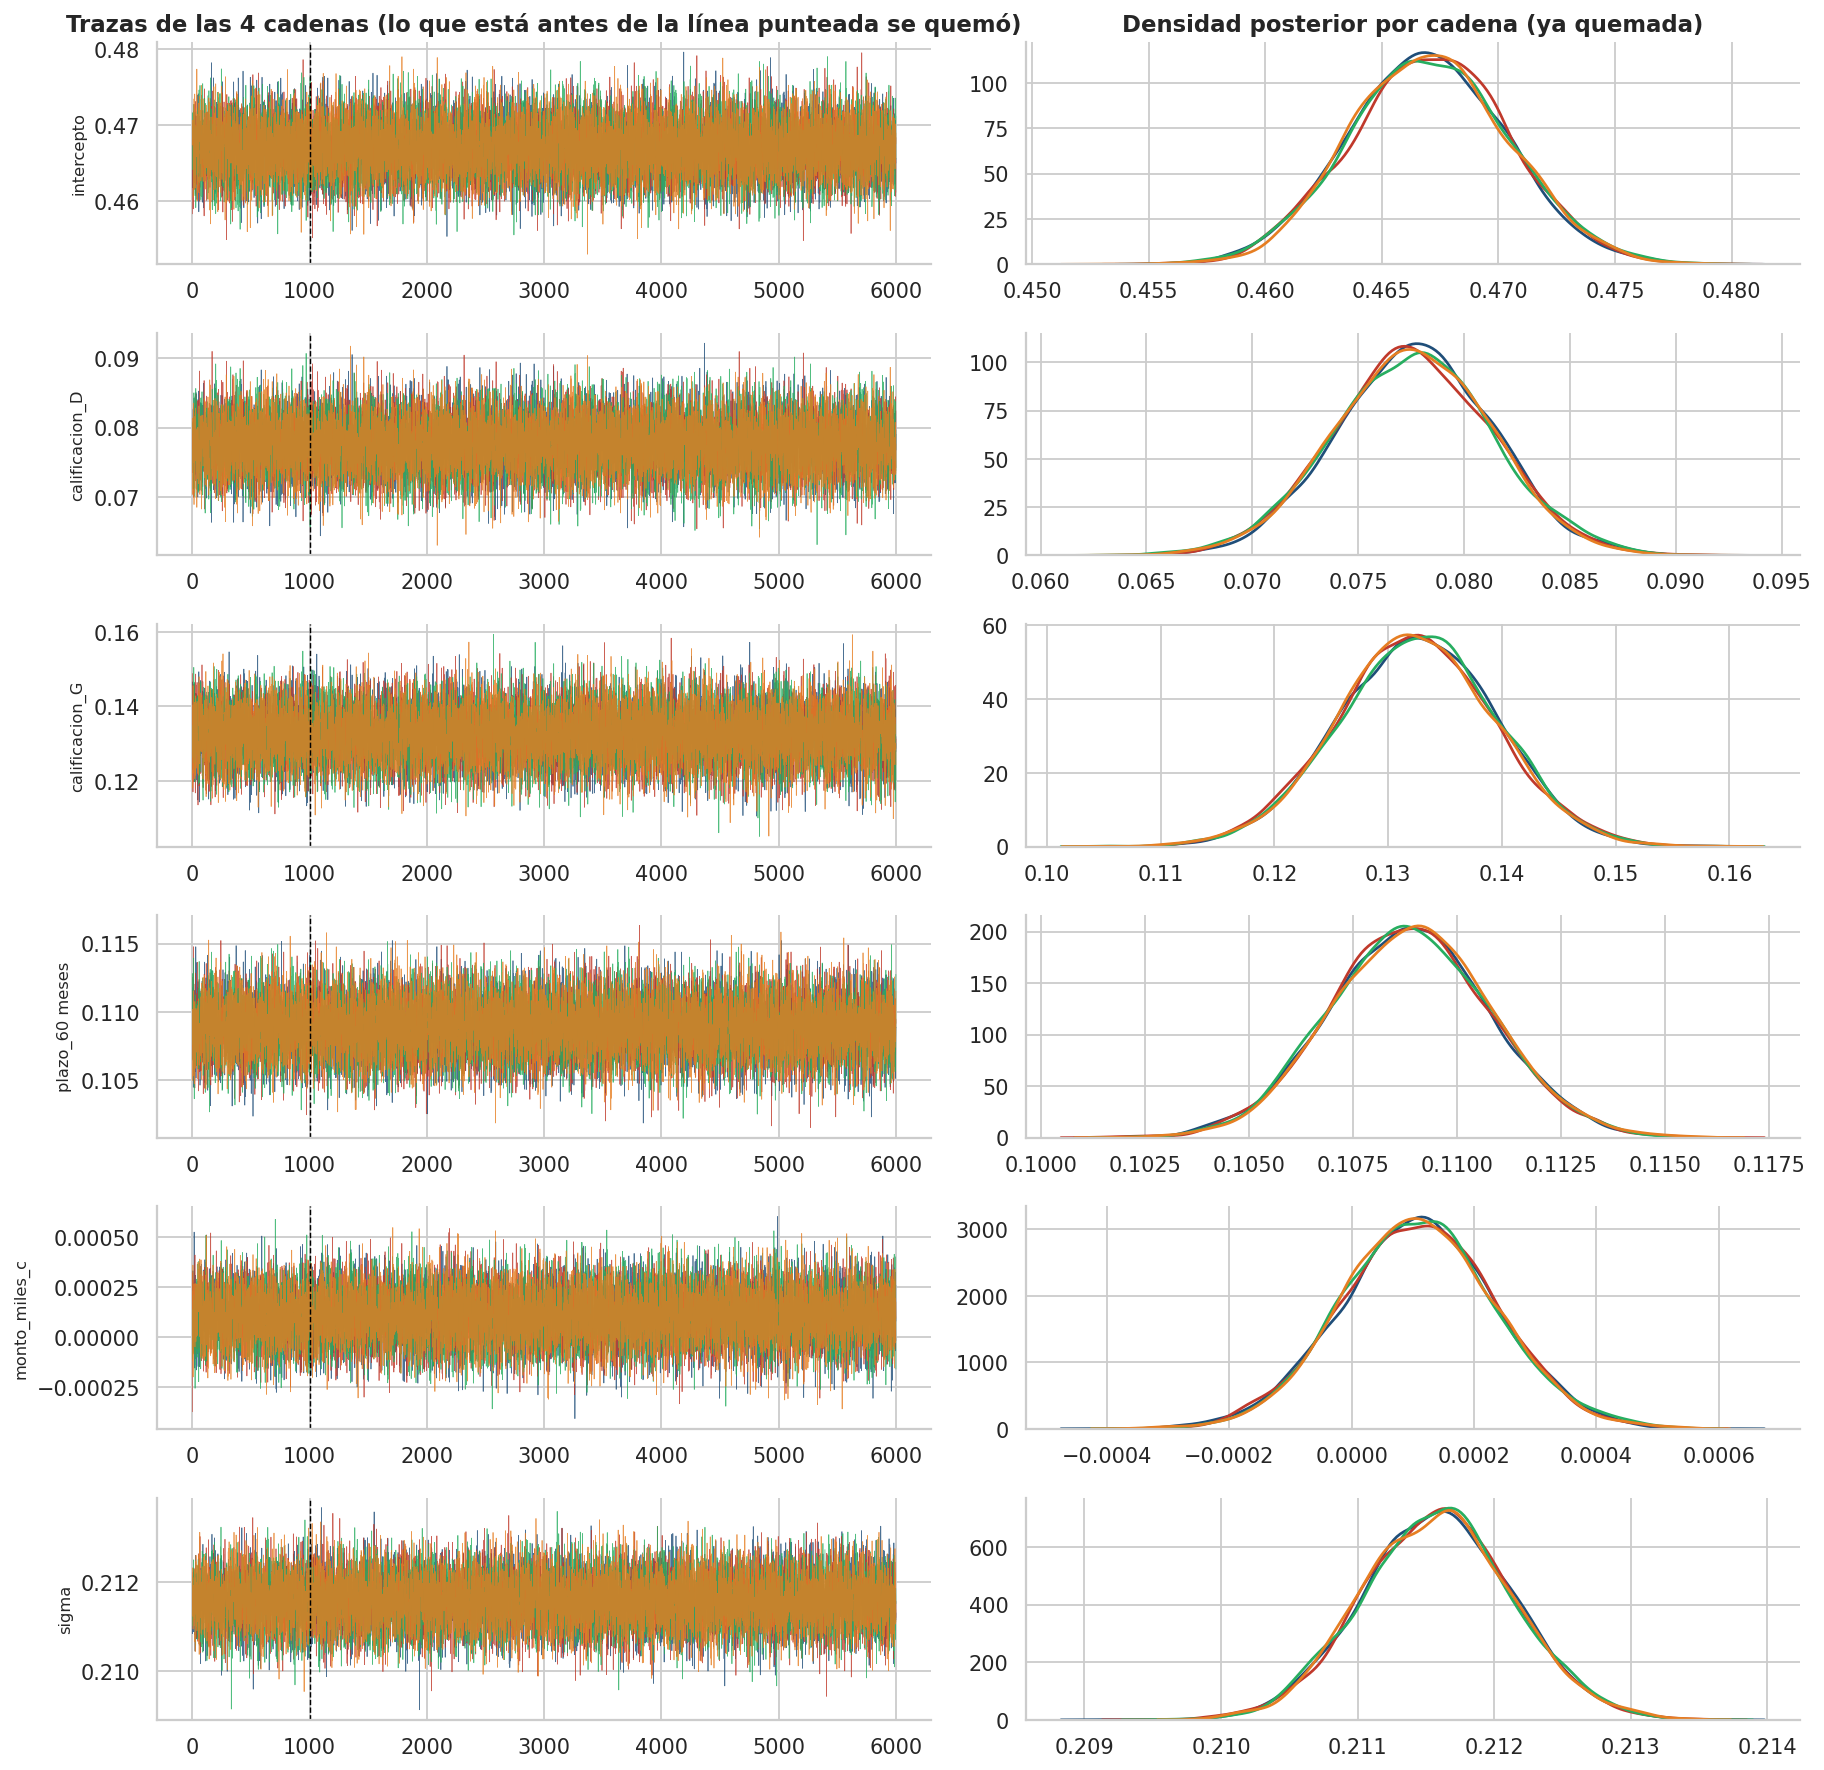

In [103]:
# Trazas: se grafica la cadena COMPLETA para que se vea el calentamiento que se quemó (antes de la línea punteada)
parametros_traza = ['intercepto', 'calificacion_D', 'calificacion_G', 'plazo_60 meses', 'monto_miles_c']
colores = ['#1f4e79', '#c0392b', '#27ae60', '#e67e22']
series = [(n, modelo.cadenas_beta_[:, :, nombres.index(n)]) for n in parametros_traza] + [('sigma', np.sqrt(modelo.cadenas_sigma2_))]
fig, ejes = plt.subplots(len(series), 2, figsize=(14, 2.3 * len(series)))
for fila, (nombre, valores) in enumerate(series):
    for k in range(modelo.n_cadenas):
        ejes[fila, 0].plot(valores[k], color=colores[k], linewidth=0.4, alpha=0.8)
        sns.kdeplot(valores[k, modelo.calentamiento:], color=colores[k], ax=ejes[fila, 1])
    ejes[fila, 0].axvline(modelo.calentamiento, color='black', linestyle='--', linewidth=0.8)
    ejes[fila, 0].set_ylabel(nombre, fontsize=9)
    ejes[fila, 1].set_ylabel('')
ejes[0, 0].set_title('Trazas de las 4 cadenas (lo que está antes de la línea punteada se quemó)')
ejes[0, 1].set_title('Densidad posterior por cadena (ya quemada)')
plt.tight_layout()
plt.show()

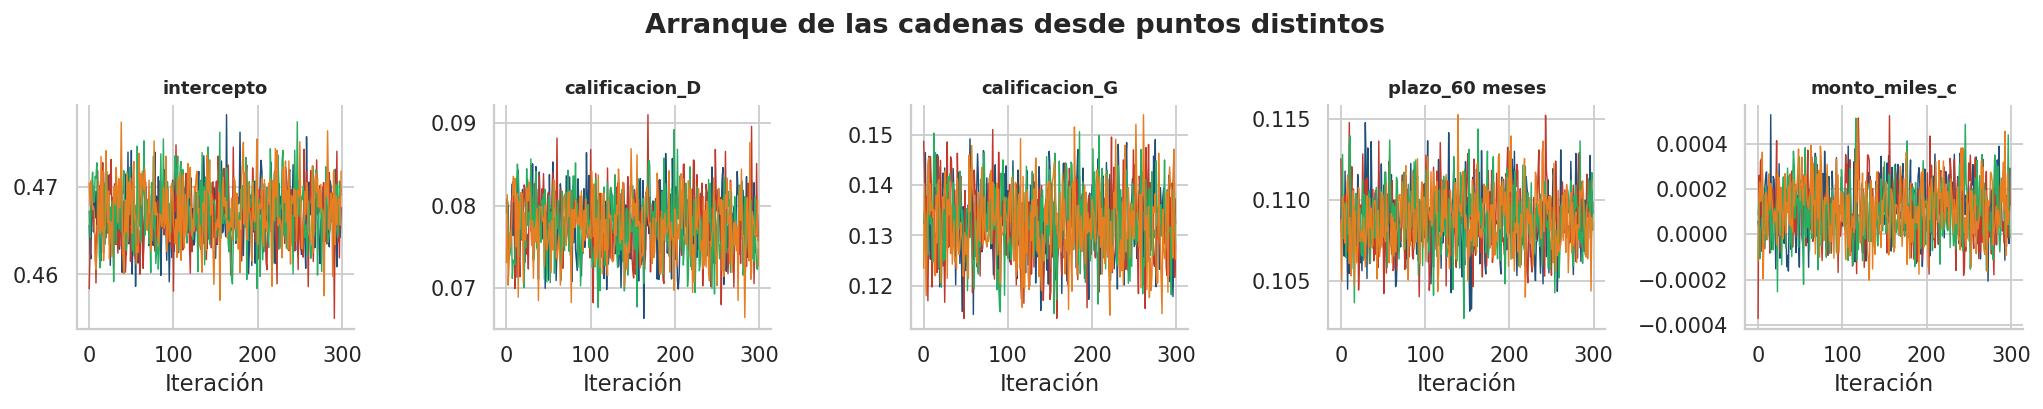

In [104]:
# Zoom a las primeras 300 iteraciones: aquí se ven los valores extraños del arranque que justifican quemar
fig, ejes = plt.subplots(1, len(parametros_traza), figsize=(16, 3.2))
for eje, nombre in zip(ejes, parametros_traza):
    for k in range(modelo.n_cadenas):
        eje.plot(modelo.cadenas_beta_[k, :300, nombres.index(nombre)], color=colores[k], linewidth=0.8)
    eje.set_title(nombre, fontsize=10)
    eje.set_xlabel('Iteración')
fig.suptitle('Arranque de las cadenas desde puntos distintos', fontweight='bold')
plt.tight_layout()
plt.show()

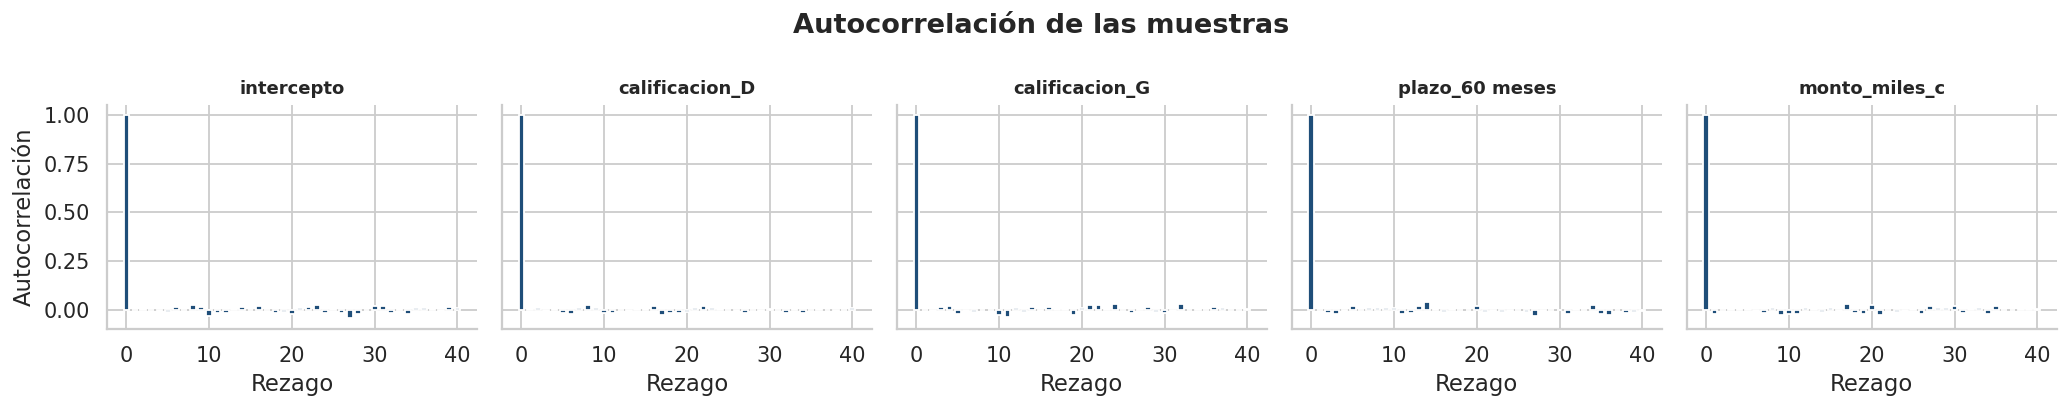

In [105]:
# Autocorrelación (cadena 1, ya quemada): debe caer rápido a cero
def autocorrelacion(serie, max_rezago=40):
    serie = serie - serie.mean()
    return np.array([1.0] + [np.corrcoef(serie[:-t], serie[t:])[0, 1] for t in range(1, max_rezago + 1)])

fig, ejes = plt.subplots(1, len(parametros_traza), figsize=(16, 3.2), sharey=True)
for eje, nombre in zip(ejes, parametros_traza):
    eje.bar(range(41), autocorrelacion(post_beta[0, :, nombres.index(nombre)]), color='#1f4e79', width=0.7)
    eje.set_title(nombre, fontsize=10)
    eje.set_xlabel('Rezago')
ejes[0].set_ylabel('Autocorrelación')
fig.suptitle('Autocorrelación de las muestras', fontweight='bold')
plt.tight_layout()
plt.show()

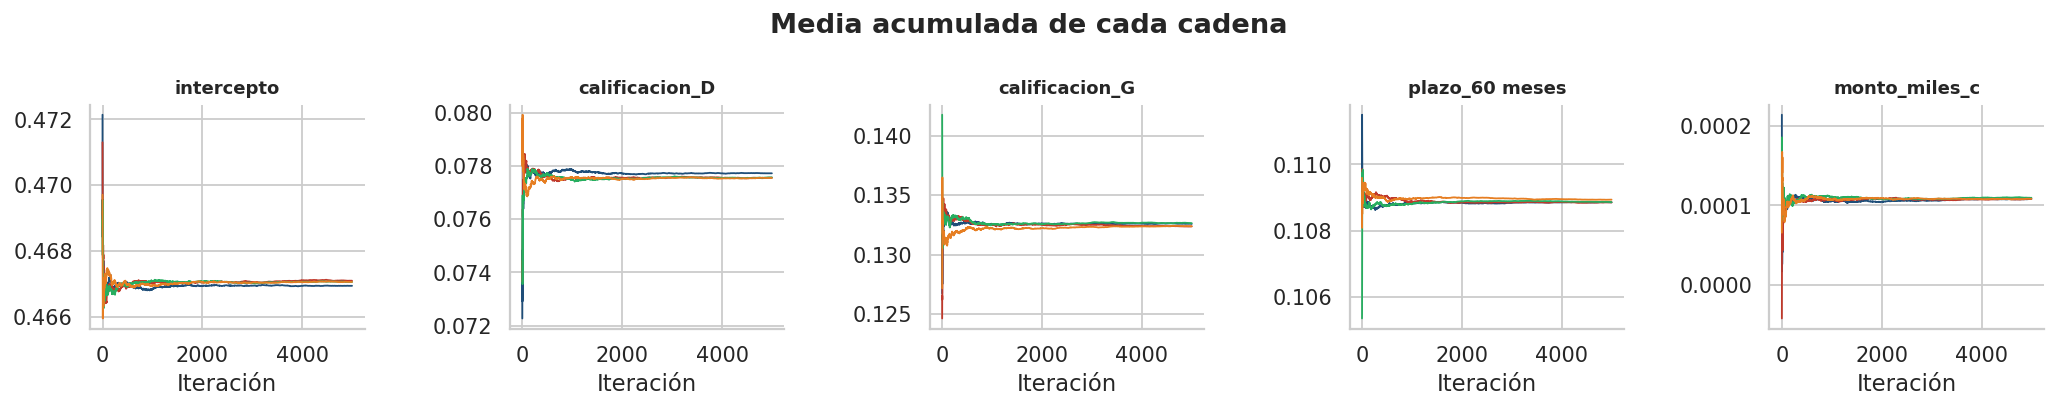

In [106]:
# Media acumulada (ya quemada): debe estabilizarse en el mismo valor en las 4 cadenas
fig, ejes = plt.subplots(1, len(parametros_traza), figsize=(16, 3.2))
for eje, nombre in zip(ejes, parametros_traza):
    for k in range(modelo.n_cadenas):
        valores = post_beta[k, :, nombres.index(nombre)]
        eje.plot(np.cumsum(valores) / np.arange(1, len(valores) + 1), color=colores[k], linewidth=1)
    eje.set_title(nombre, fontsize=10)
    eje.set_xlabel('Iteración')
fig.suptitle('Media acumulada de cada cadena', fontweight='bold')
plt.tight_layout()
plt.show()

### **3.10. Resultados de la posterior.**

In [107]:
# ===== 3.10 Resultados de la posterior (entrenamiento) =====
# Se juntan las 4 cadenas quemadas. Coeficientes en puntos porcentuales (pp) de LGD.
muestras = post_beta.reshape(-1, len(nombres))
tabla_posterior = pd.DataFrame({
    'Media posterior (pp)': muestras.mean(axis=0) * 100,
    'Límite inferior 95 % (pp)': np.percentile(muestras, 2.5, axis=0) * 100,
    'Límite superior 95 % (pp)': np.percentile(muestras, 97.5, axis=0) * 100,
    'P(efecto > 0)': (muestras > 0).mean(axis=0),
}, index=nombres)
tabla_posterior.round(2)

,Media posterior (pp),Límite inferior 95 % (pp),Límite superior 95 % (pp),P(efecto > 0)
intercepto,46.70,46.05,47.37,1.00
monto_miles_c,0.01,-0.01,0.04,0.81
log2_ingreso_c,-1.43,-1.69,-1.16,0.00
dti_c,0.02,0.00,0.04,0.99
calificacion_B,2.39,1.66,3.11,1.00
calificacion_C,4.89,4.17,5.60,1.00
calificacion_D,7.76,7.03,8.49,1.00
calificacion_E,9.79,8.99,10.59,1.00
calificacion_F,11.73,10.80,12.66,1.00
calificacion_G,13.25,11.89,14.60,1.00


In [108]:
print(f'σ posterior: media {post_sigma.mean():.4f} | intervalo 95 %: {np.percentile(post_sigma, [2.5, 97.5]).round(4)}')

σ posterior: media 0.2116 | intervalo 95 %: [0.2105 0.2127]


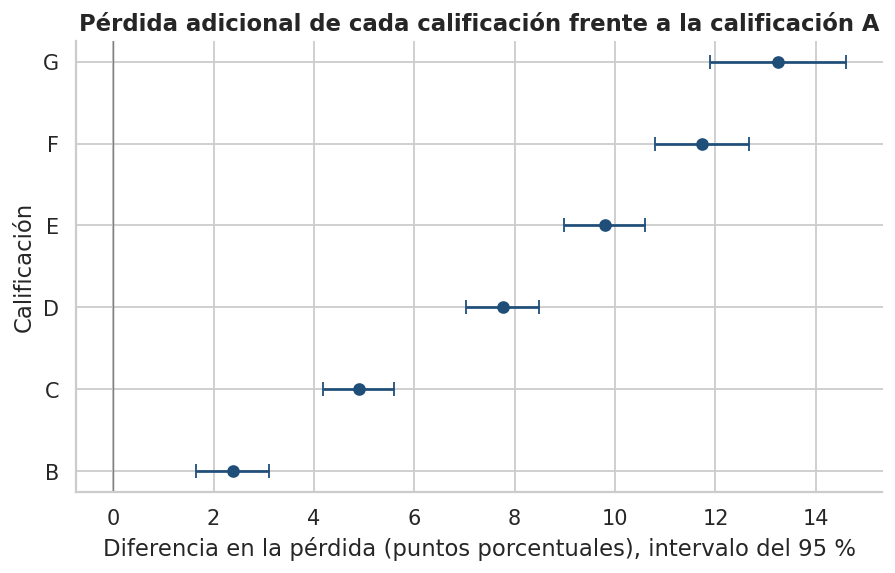

In [109]:
# Pérdida adicional de cada calificación frente a A, con intervalo de credibilidad del 95 %
efectos = tabla_posterior.loc[[n for n in nombres if n.startswith('calificacion_')]]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(efectos['Media posterior (pp)'], [n.replace('calificacion_', '') for n in efectos.index],
            xerr=[efectos['Media posterior (pp)'] - efectos['Límite inferior 95 % (pp)'],
                  efectos['Límite superior 95 % (pp)'] - efectos['Media posterior (pp)']],
            fmt='o', color='#1f4e79', capsize=4)
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_title('Pérdida adicional de cada calificación frente a la calificación A')
ax.set_xlabel('Diferencia en la pérdida (puntos porcentuales), intervalo del 95 %')
ax.set_ylabel('Calificación')
plt.show()

In [110]:
# LGD esperada por calificación para un crédito de referencia (36 meses, consolidación, características promedio)
lgd_referencia = {'A': muestras[:, 0]}
for g in ['B', 'C', 'D', 'E', 'F', 'G']:
    lgd_referencia[g] = muestras[:, 0] + muestras[:, nombres.index(f'calificacion_{g}')]
tabla_lgd_calificacion = pd.DataFrame({g: {'LGD esperada (%)': v.mean() * 100,
                                           'Límite inferior 95 % (%)': np.percentile(v, 2.5) * 100,
                                           'Límite superior 95 % (%)': np.percentile(v, 97.5) * 100}
                                       for g, v in lgd_referencia.items()}).T
tabla_lgd_calificacion.round(1)

,LGD esperada (%),Límite inferior 95 % (%),Límite superior 95 % (%)
A,46.7,46.0,47.4
B,49.1,48.7,49.5
C,51.6,51.3,51.9
D,54.5,54.1,54.8
E,56.5,56.0,57.0
F,58.4,57.7,59.1
G,60.0,58.8,61.2


In [111]:
# ¿Pierde más G que A? Probabilidad posterior
diferencia_ga = muestras[:, nombres.index('calificacion_G')] * 100
print(f'Diferencia G - A: {diferencia_ga.mean():.1f} pp | intervalo 95 %: {np.percentile(diferencia_ga, [2.5, 97.5]).round(1)} | P(G pierde más que A) = {(diferencia_ga > 0).mean():.3f}')

Diferencia G - A: 13.2 pp | intervalo 95 %: [11.9 14.6] | P(G pierde más que A) = 1.000


### **3.11. Comprobación con la base de prueba (2015).**

**Comparaciones en la prueba de 2015.** Aquí se aplican por única vez los dos criterios de éxito fijados en el Avance 2:

| Criterio | Con qué se compara | Valor de la referencia | Éxito si |
|---|---|---|---|
| **RMSE** | Línea base: predecir para los 64.846 créditos de 2015 la LGD promedio de 2007–2014 (57,3 %) | RMSE de 0,2059 | El modelo reduce el RMSE en al menos 10 % |
| **Captura@20 %** (qué parte de la pérdida total en USD concentra el 20 % de créditos priorizados) | Orden por saldo al default (priorización actual) | 40,6 % | El orden del modelo captura al menos 40,9 % |
| | Orden por calificación | 27,4 % | Referencia |
| | Máximo posible (ordenar por la pérdida real) | 41,2 % | Techo |
| | Orden al azar | 20,0 % | Piso |

$$\text{Mejora (\%)} = \left(1 - \frac{RMSE_{\text{modelo}}}{RMSE_{\text{línea base}}}\right) \times 100 \qquad\qquad \text{Captura@20\%} = \frac{\text{pérdida real en el 20 \% priorizado}}{\text{pérdida real total}} \times 100$$

In [112]:
# ===== 3.11 Se abre la base de prueba (2015): única vez que se usa =====
x_prueba = prueba[columnas_entrada]
y_prueba = prueba['lgd'].to_numpy()
prediccion_prueba = pipeline.predict(x_prueba)
linea_base = DummyRegressor(strategy='mean').fit(x_entrenamiento, y_entrenamiento)
prediccion_base = linea_base.predict(x_prueba)

In [113]:
def rmse(y_real, y_predicho):
    return np.sqrt(np.mean((y_real - y_predicho) ** 2))

rmse_modelo = rmse(y_prueba, prediccion_prueba)
rmse_linea_base = rmse(y_prueba, prediccion_base)
mejora = (1 - rmse_modelo / rmse_linea_base) * 100
print(f'RMSE modelo: {rmse_modelo:.4f} | RMSE línea base: {rmse_linea_base:.4f} | Mejora: {mejora:.1f} %')
print('Criterio de éxito (mejora de al menos 10 %):', 'CUMPLE' if mejora >= 10 else 'NO CUMPLE')

RMSE modelo: 0.1855 | RMSE línea base: 0.2059 | Mejora: 9.9 %
Criterio de éxito (mejora de al menos 10 %): NO CUMPLE


In [114]:
# Las dos referencias del RMSE en prueba, explícitas
print(f'Línea base: LGD promedio de 2007-2014 = {y_entrenamiento.mean():.4f}, predicha igual para los {len(y_prueba):,} créditos de 2015')
print(f'RMSE línea base = {rmse_linea_base:.4f} | RMSE modelo = {rmse_modelo:.4f} | Mejora = (1 - {rmse_modelo:.4f} / {rmse_linea_base:.4f}) x 100 = {mejora:.1f} %')

Línea base: LGD promedio de 2007-2014 = 0.5730, predicha igual para los 64,846 créditos de 2015
RMSE línea base = 0.2059 | RMSE modelo = 0.1855 | Mejora = (1 - 0.1855 / 0.2059) x 100 = 9.9 %


In [115]:
# Predictiva posterior en prueba: 200 muestras de la posterior simulan LGD para cada crédito de 2015
x_prueba_preparada = pipeline.named_steps['preparacion'].transform(x_prueba).to_numpy()
indices = rng.choice(len(muestras), size=200, replace=False)
sigmas = post_sigma.reshape(-1)[indices]
y_replicada = muestras[indices] @ x_prueba_preparada.T + rng.standard_normal((200, len(y_prueba))) * sigmas[:, None]
limite_inf, limite_sup = np.percentile(y_replicada, [2.5, 97.5], axis=0)
cobertura = ((y_prueba >= limite_inf) & (y_prueba <= limite_sup)).mean() * 100
fuera_rango = ((y_replicada < 0) | (y_replicada > 1)).mean() * 100
print(f'% de créditos de 2015 dentro de su intervalo predictivo del 95 %: {cobertura:.1f} %')
print(f'% de LGD simuladas fuera de [0, 1]: {fuera_rango:.1f} %')

% de créditos de 2015 dentro de su intervalo predictivo del 95 %: 97.9 %
% de LGD simuladas fuera de [0, 1]: 3.4 %


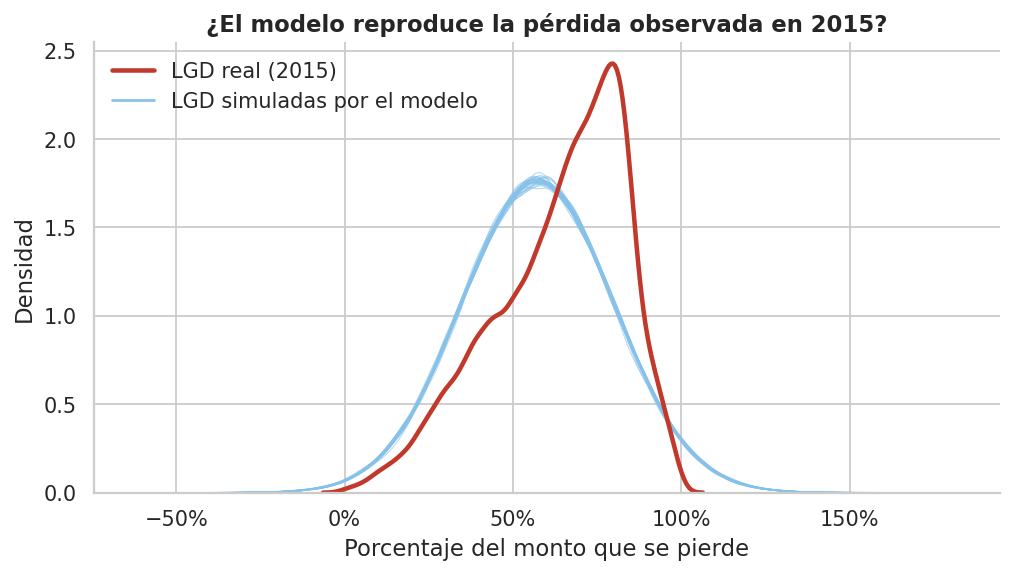

In [116]:
# Chequeo predictivo posterior: distribución simulada frente a la real
fig, ax = plt.subplots(figsize=(9, 4.5))
for r in range(30):
    sns.kdeplot(y_replicada[r], color='#85c1e9', linewidth=0.6, alpha=0.6, ax=ax)
sns.kdeplot(y_prueba, color='#c0392b', linewidth=2.5, label='LGD real (2015)', ax=ax)
ax.plot([], [], color='#85c1e9', label='LGD simuladas por el modelo')
ax.xaxis.set_major_formatter(porcentaje)
ax.set_title('¿El modelo reproduce la pérdida observada en 2015?')
ax.set_xlabel('Porcentaje del monto que se pierde')
ax.set_ylabel('Densidad')
ax.legend(frameon=False)
plt.show()

In [117]:
# Captura@20 %: % de la pérdida total en USD que queda en el 20 % de créditos priorizados
prueba['perdida_usd'] = prueba['lgd'] * prueba['monto']                     # pérdida real
prueba['saldo_default'] = prueba['monto'] - prueba['capital_pagado']        # priorización actual
prueba['calificacion_num'] = prueba['calificacion'].map({'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7})
prueba['perdida_esperada'] = prediccion_prueba * prueba['monto']           # orden del modelo

def captura_top(datos, columna_orden, proporcion=0.20):
    ordenados = datos.sort_values(columna_orden, ascending=False)
    return ordenados['perdida_usd'].iloc[: int(len(ordenados) * proporcion)].sum() / ordenados['perdida_usd'].sum() * 100

In [118]:
capturas = pd.Series({
    'Orden por saldo al default (priorización actual)': captura_top(prueba, 'saldo_default'),
    'Orden por pérdida esperada del modelo': captura_top(prueba, 'perdida_esperada'),
    'Orden por calificación (regla simple)': captura_top(prueba, 'calificacion_num'),
    'Máximo posible (pérdida real)': captura_top(prueba, 'perdida_usd'),
    'Orden al azar (esperado)': 20.0,
}, name='Captura@20 % (%)').round(1)
print(capturas)
print('Criterio de éxito (al menos 40,9 %):', 'CUMPLE' if capturas['Orden por pérdida esperada del modelo'] >= 40.9 else 'NO CUMPLE')

Orden por saldo al default (priorización actual)    40.6
Orden por pérdida esperada del modelo               39.2
Orden por calificación (regla simple)               27.4
Máximo posible (pérdida real)                       41.2
Orden al azar (esperado)                            20.0
Name: Captura@20 % (%), dtype: float64
Criterio de éxito (al menos 40,9 %): NO CUMPLE


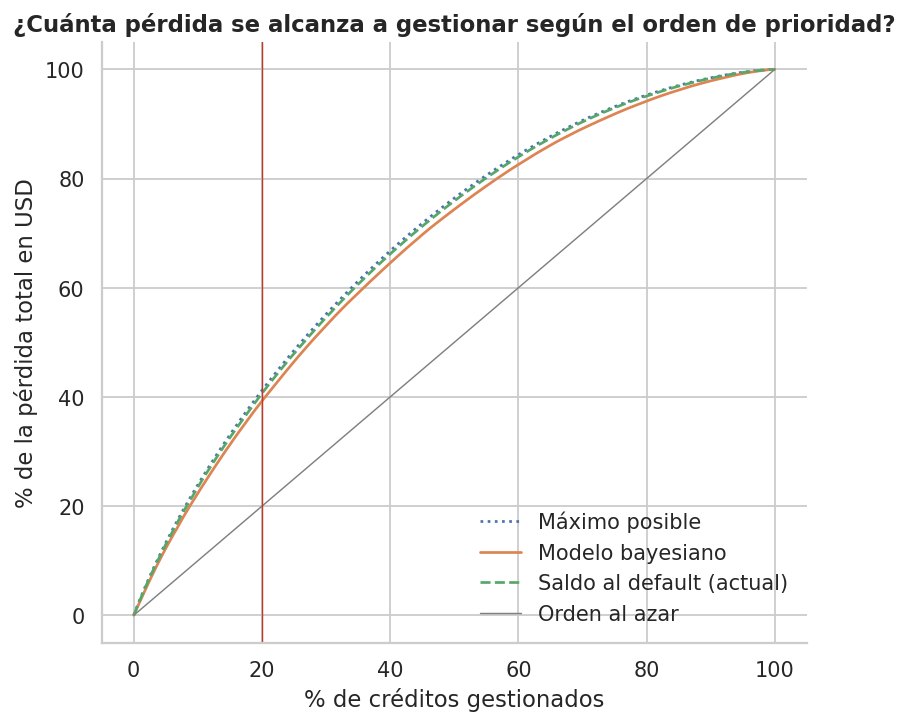

In [119]:
# Curva de ganancia acumulada
fig, ax = plt.subplots(figsize=(7, 6))
for columna, nombre, estilo in [('perdida_usd', 'Máximo posible', ':'), ('perdida_esperada', 'Modelo bayesiano', '-'),
                                ('saldo_default', 'Saldo al default (actual)', '--')]:
    ordenados = prueba.sort_values(columna, ascending=False)
    acumulado = ordenados['perdida_usd'].cumsum() / ordenados['perdida_usd'].sum() * 100
    ax.plot(np.arange(1, len(ordenados) + 1) / len(ordenados) * 100, acumulado.values, estilo, label=nombre)
ax.plot([0, 100], [0, 100], color='gray', linewidth=0.8, label='Orden al azar')
ax.axvline(20, color='#c0392b', linewidth=0.8)
ax.set_title('¿Cuánta pérdida se alcanza a gestionar según el orden de prioridad?')
ax.set_xlabel('% de créditos gestionados')
ax.set_ylabel('% de la pérdida total en USD')
ax.legend(frameon=False)
plt.show()

### **3.11.1. Incertidumbre de los resultados en prueba (análisis complementario).**

In [120]:
# RMSE y mejora según la posterior de β (intervalo de credibilidad; no cambia el veredicto)
# Con 2.000 muestras de la posterior se predice 2015 y se calcula el RMSE y la mejora frente a la línea base
indices_post = rng.choice(len(muestras), size=2000, replace=False)
rmses_post = []
for lote in np.array_split(indices_post, 20):
    predicciones = muestras[lote] @ x_prueba_preparada.T
    rmses_post.extend(np.sqrt(((predicciones - y_prueba) ** 2).mean(axis=1)))
rmses_post = np.array(rmses_post)
mejoras_post = (1 - rmses_post / rmse_linea_base) * 100
print(f'RMSE modelo: {rmses_post.mean():.4f} | IC 95 %: {np.percentile(rmses_post, [2.5, 97.5]).round(4)}')
print(f'Mejora media: {mejoras_post.mean():.2f} % | IC 95 %: {np.percentile(mejoras_post, [2.5, 97.5]).round(2)} | P(mejora >= 10 %) = {(mejoras_post >= 10).mean():.3f}')

RMSE modelo: 0.1855 | IC 95 %: [0.1849 0.186 ]
Mejora media: 9.90 % | IC 95 %: [ 9.63 10.16] | P(mejora >= 10 %) = 0.228


In [121]:
# Mejora del RMSE según la muestra de 2015 (bootstrap): se remuestrean los créditos de prueba 1.000 veces
mejoras_boot = np.empty(1000)
for b in range(1000):
    i = rng.integers(0, len(y_prueba), len(y_prueba))
    mejoras_boot[b] = (1 - rmse(y_prueba[i], prediccion_prueba[i]) / rmse(y_prueba[i], prediccion_base[i])) * 100
print(f'Mejora media: {mejoras_boot.mean():.2f} % | intervalo 95 %: {np.percentile(mejoras_boot, [2.5, 97.5]).round(2)} | P(mejora >= 10 %) = {(mejoras_boot >= 10).mean():.3f}')

Mejora media: 9.91 % | intervalo 95 %: [ 9.67 10.17] | P(mejora >= 10 %) = 0.234


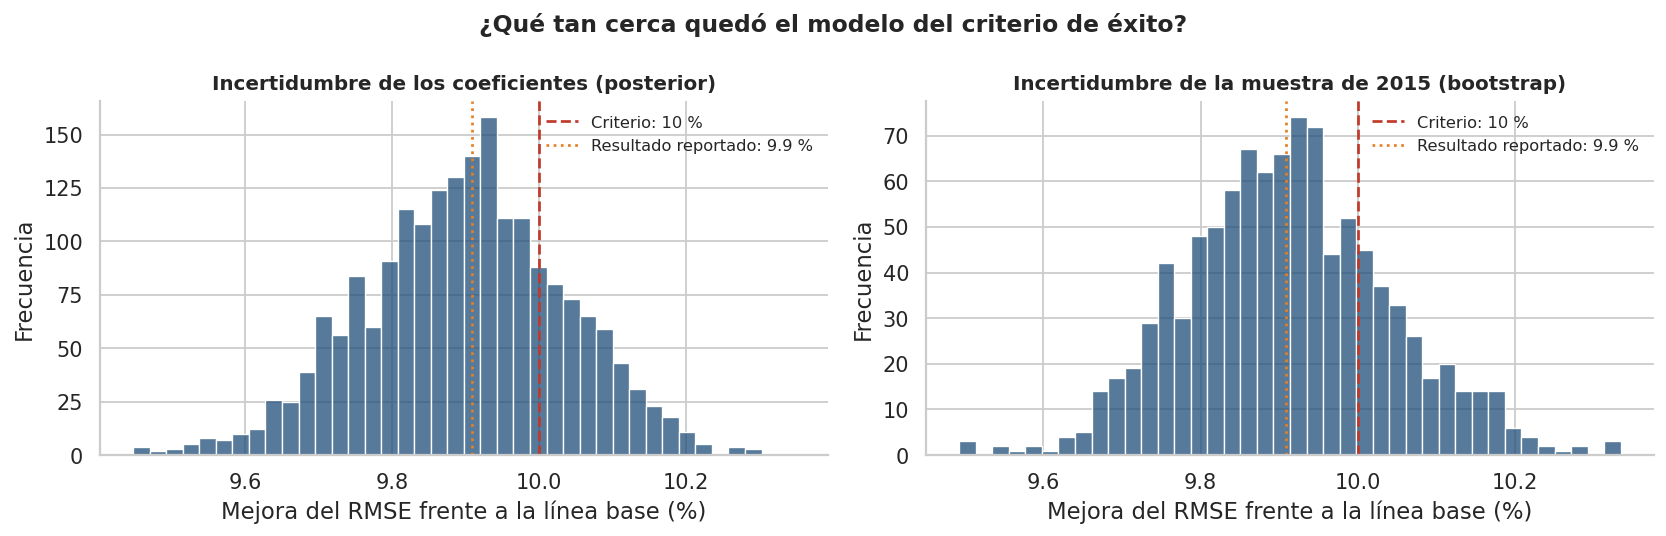

In [122]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for eje, valores, titulo in [(ejes[0], mejoras_post, 'Incertidumbre de los coeficientes (posterior)'),
                             (ejes[1], mejoras_boot, 'Incertidumbre de la muestra de 2015 (bootstrap)')]:
    sns.histplot(valores, bins=40, color='#1f4e79', ax=eje)
    eje.axvline(10, color='#c0392b', linestyle='--', label='Criterio: 10 %')
    eje.axvline(mejora, color='#e67e22', linestyle=':', label=f'Resultado reportado: {mejora:.1f} %')
    eje.set_title(titulo, fontsize=11)
    eje.set_xlabel('Mejora del RMSE frente a la línea base (%)')
    eje.set_ylabel('Frecuencia')
    eje.legend(frameon=False, fontsize=9)
fig.suptitle('¿Qué tan cerca quedó el modelo del criterio de éxito?', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

In [123]:
# Captura@20 % según la posterior de β (intervalo de credibilidad)
# Con 1.000 muestras de la posterior se recalcula la pérdida esperada y su captura en el 20 % priorizado
monto_prueba = prueba['monto'].to_numpy()
perdida_real = prueba['perdida_usd'].to_numpy()
n_top = int(len(prueba) * 0.20)
capturas_post = np.empty(1000)
for k, idx in enumerate(rng.choice(len(muestras), size=1000, replace=False)):
    esperada = (x_prueba_preparada @ muestras[idx]) * monto_prueba
    top = np.argpartition(-esperada, n_top)[:n_top]
    capturas_post[k] = perdida_real[top].sum() / perdida_real.sum() * 100
print(f'Captura@20 % del modelo: {capturas_post.mean():.2f} % | IC 95 %: {np.percentile(capturas_post, [2.5, 97.5]).round(2)} | P(captura >= 40,9 %) = {(capturas_post >= 40.9).mean():.3f}')

Captura@20 % del modelo: 39.24 % | IC 95 %: [39.23 39.25] | P(captura >= 40,9 %) = 0.000


In [124]:
# Captura@20 % según la muestra de 2015 (bootstrap): modelo, priorización actual y su diferencia, en las mismas réplicas
saldo_prueba = prueba['saldo_default'].to_numpy()
esperada_media = prueba['perdida_esperada'].to_numpy()
capt_modelo_boot, capt_saldo_boot = np.empty(1000), np.empty(1000)
for b in range(1000):
    i = rng.integers(0, len(prueba), len(prueba))
    total = perdida_real[i].sum()
    capt_modelo_boot[b] = perdida_real[i][np.argpartition(-esperada_media[i], n_top)[:n_top]].sum() / total * 100
    capt_saldo_boot[b] = perdida_real[i][np.argpartition(-saldo_prueba[i], n_top)[:n_top]].sum() / total * 100
diferencia_capt_boot = capt_modelo_boot - capt_saldo_boot
print(f'Modelo: {capt_modelo_boot.mean():.2f} % | IC 95 %: {np.percentile(capt_modelo_boot, [2.5, 97.5]).round(2)}')
print(f'Saldo al default: {capt_saldo_boot.mean():.2f} % | IC 95 %: {np.percentile(capt_saldo_boot, [2.5, 97.5]).round(2)}')
print(f'Diferencia modelo - saldo: {diferencia_capt_boot.mean():.2f} pp | IC 95 %: {np.percentile(diferencia_capt_boot, [2.5, 97.5]).round(2)} | P(modelo > saldo) = {(diferencia_capt_boot > 0).mean():.3f}')

Modelo: 39.24 % | IC 95 %: [39.07 39.4 ]
Saldo al default: 40.64 % | IC 95 %: [40.49 40.78]
Diferencia modelo - saldo: -1.40 pp | IC 95 %: [-1.46 -1.33] | P(modelo > saldo) = 0.000


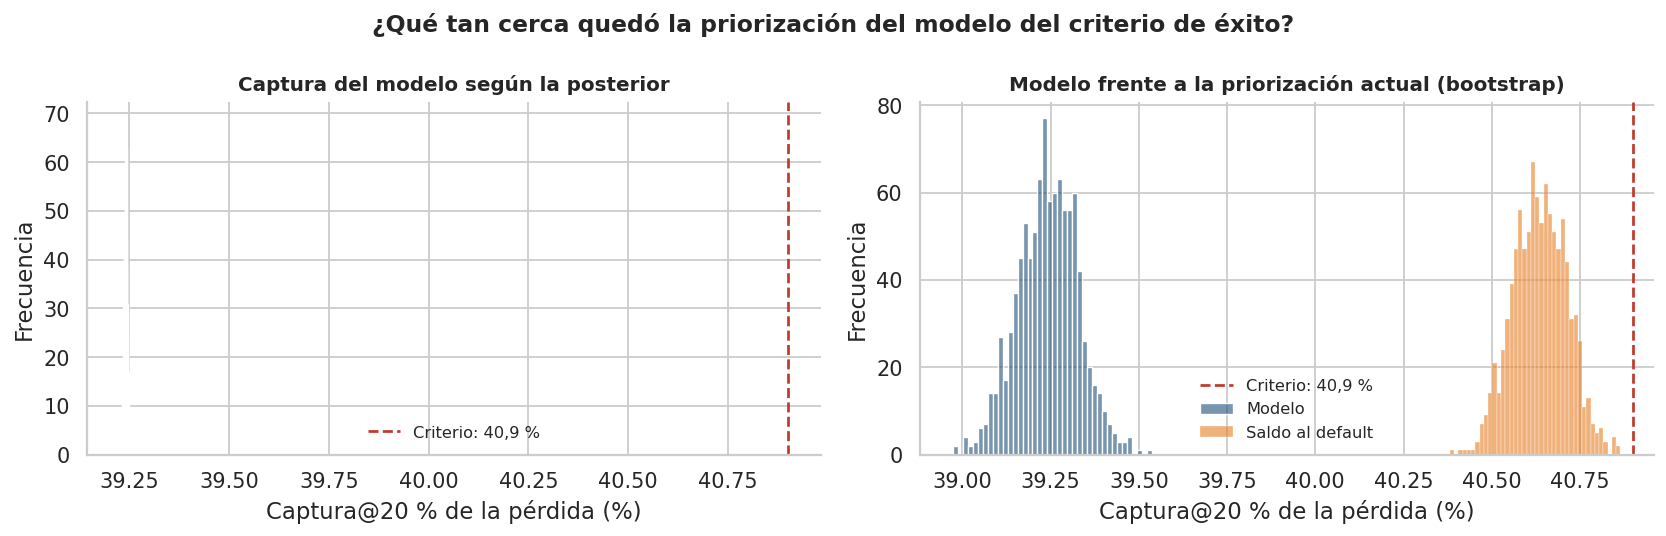

In [125]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(capturas_post, bins=40, color='#1f4e79', ax=ejes[0])
ejes[0].set_title('Captura del modelo según la posterior', fontsize=11)
sns.histplot(capt_modelo_boot, bins=40, color='#1f4e79', alpha=0.6, label='Modelo', ax=ejes[1])
sns.histplot(capt_saldo_boot, bins=40, color='#e67e22', alpha=0.6, label='Saldo al default', ax=ejes[1])
ejes[1].set_title('Modelo frente a la priorización actual (bootstrap)', fontsize=11)
for eje in ejes:
    eje.axvline(40.9, color='#c0392b', linestyle='--', label='Criterio: 40,9 %')
    eje.set_xlabel('Captura@20 % de la pérdida (%)')
    eje.set_ylabel('Frecuencia')
    eje.legend(frameon=False, fontsize=9)
fig.suptitle('¿Qué tan cerca quedó la priorización del modelo del criterio de éxito?', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

### **3.12. Análisis exploratorio: tasa de interés relativa a su calificación.**

In [126]:
# ===== 3.12 ANÁLISIS EXPLORATORIO, POSTERIOR AL RESULTADO DEL MODELO PRINCIPAL =====
# Se hace DESPUÉS de ver la prueba de 2015, por eso NO cambia el veredicto de las secciones 3.11 y 3.13.
# Idea: la tasa se excluyó porque repite la información de la calificación (VIF 9,7).
# En lugar de borrarla, se usa la tasa RELATIVA a su calificación:
#     tasa relativa = tasa del crédito - tasa promedio de su calificación (aprendida solo del entrenamiento)
# Así queda solo la parte de la tasa que la calificación NO explica, y deja de repetirse con ella.
# Se lee: "un crédito que paga 1 punto más de tasa que el promedio de su misma calificación, ¿pierde más?"
class PreparacionLGDTasa(PreparacionLGD):
    def fit(self, X, y=None):
        super().fit(X, y)
        self.tasa_media_calificacion_ = X.groupby('calificacion')['tasa'].mean()
        return self

    def transform(self, X):
        salida = super().transform(X)
        salida['tasa_relativa'] = X['tasa'] - X['calificacion'].map(self.tasa_media_calificacion_)
        return salida

In [127]:
# Mismas predictoras del modelo principal + la tasa (que se transforma dentro del pipeline)
columnas_entrada_tasa = columnas_entrada + ['tasa']
x_entrenamiento_tasa = entrenamiento[columnas_entrada_tasa]
x_prueba_tasa = prueba[columnas_entrada_tasa]

In [128]:
# Tasa promedio por calificación en el entrenamiento (lo que se le resta a cada crédito)
preparacion_tasa = PreparacionLGDTasa().fit(x_entrenamiento_tasa)
preparacion_tasa.tasa_media_calificacion_.round(2)

,tasa
calificacion,
A,7.81
B,11.68
C,14.73
D,17.58
E,20.56
F,23.61
G,24.93


In [129]:
# Cómo queda la tasa relativa: promedio 0 en cada calificación, y su dispersión dentro de cada grado
x_preparada_tasa = preparacion_tasa.transform(x_entrenamiento_tasa)
x_preparada_tasa.groupby(entrenamiento['calificacion'])['tasa_relativa'].describe()[['count', 'mean', 'std', 'min', 'max']].round(2)

,count,mean,std,min,max
calificacion,,,,,
A,4166.0,0.0,0.91,-2.39,1.82
B,15015.0,-0.0,1.28,-5.68,2.41
C,21924.0,-0.0,1.20,-8.73,2.54
D,17726.0,0.0,1.36,-5.72,2.73
E,10541.0,0.0,1.59,-14.56,2.84
F,4516.0,0.0,1.66,-8.60,1.96
G,1287.0,-0.0,1.98,-8.34,1.13


In [130]:
# Verificación: con la tasa relativa ya no hay multicolinealidad (VIF de todas las predictoras)
x_sin_intercepto_tasa = x_preparada_tasa.drop(columns='intercepto')
vif_tasa = pd.Series(np.diag(np.linalg.inv(x_sin_intercepto_tasa.corr().to_numpy())), index=x_sin_intercepto_tasa.columns, name='VIF')
vif_tasa.sort_values(ascending=False).round(2)

,VIF
calificacion_C,4.61
calificacion_D,4.28
calificacion_B,3.71
calificacion_E,3.41
calificacion_F,2.19
monto_miles_c,1.91
log2_ingreso_c,1.57
plazo_60 meses,1.52
calificacion_G,1.37
proposito_Otro,1.12


In [131]:
# Prior de la tasa relativa: media 0 (no se supone dirección) y desviación 0,02:
# por cada punto de tasa por encima del promedio de su calificación, la pérdida cambiaría como mucho ±4 pp.
# Las demás priors son las mismas del modelo principal.
prior_grupos_tasa = {**prior_grupos, 'tasa_relativa': (0.0, 0.02)}

In [132]:
# Pipeline exploratorio: misma configuración del principal (4 cadenas, 6.000 iteraciones, 1.000 de calentamiento, misma semilla)
pipeline_tasa = Pipeline([
    ('preparacion', PreparacionLGDTasa(umbral_proposito=0.01)),
    ('modelo', RegresionBayesianaGibbs(prior_grupos=prior_grupos_tasa, nu0=nu0, s02=s02,
                                       n_cadenas=4, n_iter=6000, calentamiento=1000, semilla=semilla)),
])

In [133]:
# Validación cruzada con EXACTAMENTE los mismos pliegues de tiempo del modelo principal
cv_tasa = cross_validate(pipeline_tasa, x_entrenamiento_tasa, y_entrenamiento, cv=cortes,
                         scoring='neg_root_mean_squared_error', return_train_score=True)
tabla_cv_tasa = pd.DataFrame({
    'Valida con': [v for _, v in pliegues],
    'RMSE validación (principal)': -cv_modelo['test_score'],
    'RMSE validación (con tasa relativa)': -cv_tasa['test_score'],
    'RMSE validación (línea base)': -cv_base['test_score'],
})
tabla_cv_tasa['Mejora principal (%)'] = (1 - tabla_cv_tasa['RMSE validación (principal)'] / tabla_cv_tasa['RMSE validación (línea base)']) * 100
tabla_cv_tasa['Mejora con tasa relativa (%)'] = (1 - tabla_cv_tasa['RMSE validación (con tasa relativa)'] / tabla_cv_tasa['RMSE validación (línea base)']) * 100
tabla_cv_tasa.round(4)

,Valida con,RMSE validación (principal),RMSE validación (con tasa relativa),RMSE validación (línea base),Mejora principal (%),Mejora con tasa relativa (%)
0,2012,0.2393,0.2401,0.2460,2.7325,2.4227
1,2013,0.2153,0.2153,0.2243,4.0160,4.0203
2,2014,0.1981,0.1981,0.2143,7.5698,7.5679


In [134]:
# Ajuste con todo el entrenamiento
pipeline_tasa.fit(x_entrenamiento_tasa, y_entrenamiento)
modelo_tasa = pipeline_tasa.named_steps['modelo']
nombres_tasa = modelo_tasa.nombres_
post_beta_tasa = modelo_tasa.post_beta_
muestras_tasa = post_beta_tasa.reshape(-1, len(nombres_tasa))

In [135]:
# Convergencia (cadenas ya quemadas)
diagnosticos_tasa = pd.DataFrame({
    'R-hat': [r_hat(post_beta_tasa[:, :, j]) for j in range(len(nombres_tasa))] + [r_hat(modelo_tasa.post_sigma_)],
    'ESS': [ess(post_beta_tasa[:, :, j]) for j in range(len(nombres_tasa))] + [ess(modelo_tasa.post_sigma_)],
}, index=nombres_tasa + ['sigma'])
print(f"R-hat máximo: {diagnosticos_tasa['R-hat'].max():.4f} | ESS mínimo: {diagnosticos_tasa['ESS'].min():,.0f}")

R-hat máximo: 1.0003 | ESS mínimo: 20,000


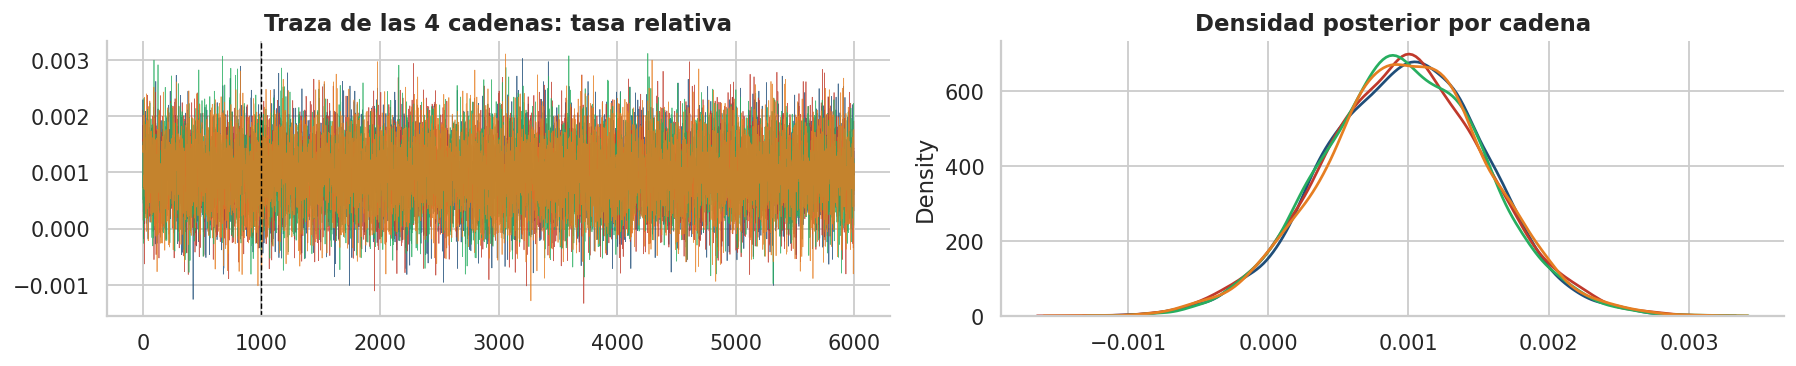

In [136]:
# Traza del nuevo coeficiente (cadena completa; lo que está antes de la línea punteada se quemó)
fig, ejes = plt.subplots(1, 2, figsize=(14, 3))
j = nombres_tasa.index('tasa_relativa')
for k in range(modelo_tasa.n_cadenas):
    ejes[0].plot(modelo_tasa.cadenas_beta_[k, :, j], color=colores[k], linewidth=0.4, alpha=0.8)
    sns.kdeplot(post_beta_tasa[k, :, j], color=colores[k], ax=ejes[1])
ejes[0].axvline(modelo_tasa.calentamiento, color='black', linestyle='--', linewidth=0.8)
ejes[0].set_title('Traza de las 4 cadenas: tasa relativa')
ejes[1].set_title('Densidad posterior por cadena')
plt.tight_layout()
plt.show()

In [137]:
# Efecto de la tasa relativa: pp de pérdida por cada punto de tasa por encima del promedio de su calificación
efecto_tasa = muestras_tasa[:, nombres_tasa.index('tasa_relativa')] * 100
print(f'Efecto de la tasa relativa: {efecto_tasa.mean():.2f} pp por punto | intervalo 95 %: {np.percentile(efecto_tasa, [2.5, 97.5]).round(2)} | P(> 0) = {(efecto_tasa > 0).mean():.3f}')

Efecto de la tasa relativa: 0.10 pp por punto | intervalo 95 %: [-0.02  0.21] | P(> 0) = 0.952


In [138]:
# ¿Cambian los demás coeficientes al agregar la tasa relativa? (pp, medias posteriores)
comparacion_coef = pd.DataFrame({
    'Modelo principal (pp)': pd.Series(muestras.mean(axis=0) * 100, index=nombres),
    'Con tasa relativa (pp)': pd.Series(muestras_tasa.mean(axis=0) * 100, index=nombres_tasa),
})
comparacion_coef['Cambio (pp)'] = comparacion_coef['Con tasa relativa (pp)'] - comparacion_coef['Modelo principal (pp)']
comparacion_coef.round(2)

,Modelo principal (pp),Con tasa relativa (pp),Cambio (pp)
calificacion_B,2.39,2.40,0.01
calificacion_C,4.89,4.90,0.01
calificacion_D,7.76,7.78,0.02
calificacion_E,9.79,9.82,0.02
calificacion_F,11.73,11.76,0.03
calificacion_G,13.25,13.28,0.03
dti_c,0.02,0.02,-0.00
intercepto,46.70,46.69,-0.01
log2_ingreso_c,-1.43,-1.42,0.01
monto_miles_c,0.01,0.01,-0.00


In [139]:
# Evaluación en la prueba de 2015 (exploratoria)
prediccion_prueba_tasa = pipeline_tasa.predict(x_prueba_tasa)
rmse_tasa = rmse(y_prueba, prediccion_prueba_tasa)
mejora_tasa = (1 - rmse_tasa / rmse_linea_base) * 100
prueba['perdida_esperada_tasa'] = prediccion_prueba_tasa * prueba['monto']
captura_tasa = captura_top(prueba, 'perdida_esperada_tasa')
print(f'RMSE con tasa relativa: {rmse_tasa:.4f} | Mejora frente a la línea base: {mejora_tasa:.1f} % | Captura@20 %: {captura_tasa:.1f} %')

RMSE con tasa relativa: 0.1858 | Mejora frente a la línea base: 9.8 % | Captura@20 %: 39.2 %


In [140]:
# Intervalo de credibilidad de la mejora del RMSE del modelo exploratorio (misma línea base del principal)
x_prueba_tasa_preparada = pipeline_tasa.named_steps['preparacion'].transform(x_prueba_tasa).to_numpy()
indices_tasa = rng.choice(len(muestras_tasa), size=2000, replace=False)
rmses_tasa_post = np.concatenate([np.sqrt(((muestras_tasa[lote] @ x_prueba_tasa_preparada.T - y_prueba) ** 2).mean(axis=1))
                                  for lote in np.array_split(indices_tasa, 20)])
mejoras_tasa_post = (1 - rmses_tasa_post / rmse_linea_base) * 100
print(f'Mejora con tasa relativa: {mejora_tasa:.1f} % | IC 95 %: {np.percentile(mejoras_tasa_post, [2.5, 97.5]).round(2)} | P(mejora >= 10 %) = {(mejoras_tasa_post >= 10).mean():.3f}')

Mejora con tasa relativa: 9.8 % | IC 95 %: [ 9.39 10.08] | P(mejora >= 10 %) = 0.066


In [141]:
# Los 13 créditos con tasa de 6 % en grados B a G quedan con tasa relativa muy negativa: ¿cuántos hay en entrenamiento y prueba?
print(f"En entrenamiento: {((entrenamiento['tasa'] == 6.00) & (entrenamiento['calificacion'] != 'A')).sum()} | En prueba: {((prueba['tasa'] == 6.00) & (prueba['calificacion'] != 'A')).sum()}")

En entrenamiento: 3 | En prueba: 5


In [142]:
# Comparación final: modelo principal (el que cuenta para el veredicto) frente al exploratorio
tabla_exploratoria = pd.DataFrame({
    'Modelo principal': [f"{tabla_cv['Mejora frente a la línea base (%)'].mean():.1f} %", f'{rmse_modelo:.4f}', f'{mejora:.1f} %',
                         f"{capturas['Orden por pérdida esperada del modelo']:.1f} %", f'{diferencia_ga.mean():.1f}', '—',
                         f"{diagnosticos['R-hat'].max():.4f}"],
    'Con tasa relativa (exploratorio)': [f"{tabla_cv_tasa['Mejora con tasa relativa (%)'].mean():.1f} %", f'{rmse_tasa:.4f}', f'{mejora_tasa:.1f} %',
                                         f'{captura_tasa:.1f} %', f"{muestras_tasa[:, nombres_tasa.index('calificacion_G')].mean() * 100:.1f}",
                                         f'{efecto_tasa.mean():.2f} pp por punto', f"{diagnosticos_tasa['R-hat'].max():.4f}"],
}, index=['Mejora promedio en validación cruzada', 'RMSE en prueba 2015', 'Mejora del RMSE (criterio: 10 %)',
          'Captura@20 % (criterio: 40,9 %)', 'Diferencia G - A (pp)', 'Efecto de la tasa relativa', 'R-hat máximo'])
with pd.option_context('display.max_colwidth', None):
    display(tabla_exploratoria)

,Modelo principal,Con tasa relativa (exploratorio)
Mejora promedio en validación cruzada,4.8 %,4.7 %
RMSE en prueba 2015,0.1855,0.1858
Mejora del RMSE (criterio: 10 %),9.9 %,9.8 %
"Captura@20 % (criterio: 40,9 %)",39.2 %,39.2 %
Diferencia G - A (pp),13.2,13.3
Efecto de la tasa relativa,—,0.10 pp por punto
R-hat máximo,1.0002,1.0003


### **3.13. Resumen final del proyecto.**

In [143]:
# ===== 3.13 Tabla final: todo lo que se hizo y se encontró, con intervalos del 95 % y con qué se comparó =====
ic = lambda v, d=1, u='': f'[{np.percentile(v, 2.5):.{d}f}{u}; {np.percentile(v, 97.5):.{d}f}{u}]'
fila = lambda etapa, concepto, valor, intervalo='—', referencia='—': {
    'Etapa': etapa, 'Concepto': concepto, 'Valor': valor, 'Intervalo del 95 %': intervalo, 'Comparado con': referencia}
coef = lambda nombre: muestras[:, nombres.index(nombre)] * 100
diferencia_ga_simple = (fenomeno.loc['G', 'mean'] - fenomeno.loc['A', 'mean']) * 100
propositos_modelo = [n for n in nombres if n.startswith('proposito_')]
prop_max = max(propositos_modelo, key=lambda n: coef(n).mean())
prop_min = min(propositos_modelo, key=lambda n: coef(n).mean())

tabla_final = pd.DataFrame([
    fila('Datos', 'Filas leídas de Kaggle', f'{len(df) + id_numerico.isna().sum():,}'),
    fila('Datos', 'Filas que no son créditos (resúmenes)', f'{id_numerico.isna().sum():,}'),
    fila('Datos', 'Créditos con características idénticas a otro', f'{iguales.sum():,}'),
    fila('Población', 'Créditos castigados (incluye fuera de política)', f'{len(df_def):,}'),
    fila('Población', 'Créditos En incumplimiento excluidos', f"{(df['estado'] == 'En incumplimiento').sum():,}"),
    fila('Fenómeno', 'Diferencia de pérdida promedio G - A, sin ajustar (pp)', f'{diferencia_ga_simple:.1f}', referencia='Promedios simples de todos los castigados'),
    fila('Censura', 'Fecha de corte', fecha_corte.strftime('%Y-%m')),
    fila('Censura', 'Coincidencia de fechas de default (±6 meses)', f'{(diferencia.abs() <= 6).mean() * 100:.1f} %', referencia='Fecha estimada por cuotas pagadas'),
    fila('Censura', 'Ventana de maduración (meses)', ventana),
    fila('Censura', 'Excluidos por la ventana', f'{len(df_def) - len(df_modelo):,}'),
    fila('Censura', 'Créditos tras la ventana (df_modelo)', f'{len(df_modelo):,}'),
    fila('Variables', 'VIF tasa - calificación (la tasa se excluye)', f'{1 / (1 - r2_vif):.1f}', referencia='Criterio: VIF menor que 5'),
    fila('Variables', 'Correlación de Spearman de la utilización con la pérdida (se excluye)', f"{con_util['utilizacion'].corr(con_util['lgd'], method='spearman'):.3f}",
         referencia=f"Monto: {con_util['monto'].corr(con_util['lgd'], method='spearman'):.3f}"),
    fila('Variables', 'VIF máximo de las predictoras finales', f'{vif_final.max():.2f} ({vif_final.idxmax()})', referencia='Criterio: VIF menor que 5'),
    fila('Variables', 'Propósitos agrupados en Otro (< 1 %)', ', '.join(preparacion.propositos_agrupados_) or 'Ninguno'),
    fila('Ajuste', 'Excluidos para el ajuste (ingreso <= 0, dti vacío o > 100)', f'{excluir.sum():,}'),
    fila('Ajuste', 'Base de ajuste (df_ajuste)', f'{len(df_ajuste):,}'),
    fila('Partición', 'Entrenamiento 2007-2014', f'{len(entrenamiento):,}'),
    fila('Partición', 'Prueba 2015', f'{len(prueba):,}'),
    fila('Modelo', 'Coeficientes', len(nombres)),
    fila('Modelo', 'Cadenas x iteraciones conservadas (tras quemar 1.000 por cadena)', f'{modelo.n_cadenas} x {modelo.n_iter - modelo.calentamiento:,}'),
    fila('Convergencia', 'R-hat máximo', f"{diagnosticos['R-hat'].max():.4f}", referencia='Criterio: menor que 1,01'),
    fila('Convergencia', 'ESS mínimo', f"{diagnosticos['ESS'].min():,.0f}", referencia=f'Máximo posible: {post_beta.shape[0] * post_beta.shape[1]:,}'),
] + [
    fila('Validación cruzada', f"Mejora del RMSE al validar {int(r['Valida con'])} (%)", f"{r['Mejora (%)']:.1f}",
         f"[{r['IC 95 % inferior']:.1f}; {r['IC 95 % superior']:.1f}]", f"Línea base del pliegue: RMSE {r['RMSE línea base']:.4f}")
    for _, r in tabla_cv_ic.iterrows()
] + [
    fila('Validación cruzada', 'Mejora promedio frente a la línea base (%)', f"{tabla_cv['Mejora frente a la línea base (%)'].mean():.1f}", referencia='Promedio de los tres pliegues'),
    fila('Resultados', 'Diferencia G - A con lo demás igual (pp)', f"{coef('calificacion_G').mean():.1f}", ic(coef('calificacion_G')), f'Sin ajustar: {diferencia_ga_simple:.1f} pp'),
    fila('Resultados', 'P(G pierde más que A)', f"{(coef('calificacion_G') > 0).mean():.3f}"),
    fila('Resultados', 'Diferencia plazo 60 meses (pp)', f"{coef('plazo_60 meses').mean():.1f}", ic(coef('plazo_60 meses')), 'Plazo de 36 meses'),
    fila('Resultados', f"Propósito que más pierde: {prop_max.replace('proposito_', '')} (pp)", f'{coef(prop_max).mean():.1f}', ic(coef(prop_max)), 'Consolidación de deudas'),
    fila('Resultados', f"Propósito que menos pierde: {prop_min.replace('proposito_', '')} (pp)", f'{coef(prop_min).mean():.1f}', ic(coef(prop_min)), 'Consolidación de deudas'),
    fila('Resultados', 'LGD esperada de un crédito A de referencia (%)', f"{lgd_referencia['A'].mean() * 100:.1f}", ic(lgd_referencia['A'] * 100), '36 meses, consolidación, características promedio'),
    fila('Resultados', 'LGD esperada de un crédito G de referencia (%)', f"{lgd_referencia['G'].mean() * 100:.1f}", ic(lgd_referencia['G'] * 100), '36 meses, consolidación, características promedio'),
    fila('Resultados', 'Desviación del error (σ)', f'{post_sigma.mean():.4f}', ic(post_sigma, 4)),
    fila('Prueba 2015', 'RMSE modelo', f'{rmse_modelo:.4f}', ic(rmses_post, 4), f'Línea base (LGD promedio 2007-2014): {rmse_linea_base:.4f}'),
    fila('Prueba 2015', 'Mejora del RMSE (%), intervalo de credibilidad', f'{mejora:.1f}', ic(mejoras_post, 2), f"Criterio: al menos 10 % ({'cumple' if mejora >= 10 else 'no cumple'})"),
    fila('Prueba 2015', 'Mejora del RMSE (%), intervalo bootstrap', f'{mejora:.1f}', ic(mejoras_boot, 2), 'Criterio: al menos 10 %'),
    fila('Prueba 2015', 'P(mejora >= 10 %) posterior | bootstrap', f'{(mejoras_post >= 10).mean():.3f} | {(mejoras_boot >= 10).mean():.3f}'),
    fila('Prueba 2015', 'Captura@20 % del modelo (%), intervalo de credibilidad', f"{capturas['Orden por pérdida esperada del modelo']:.1f}", ic(capturas_post),
         f"Criterio: al menos 40,9 % ({'cumple' if capturas['Orden por pérdida esperada del modelo'] >= 40.9 else 'no cumple'})"),
    fila('Prueba 2015', 'Captura@20 % del modelo (%), intervalo bootstrap', f"{capturas['Orden por pérdida esperada del modelo']:.1f}", ic(capt_modelo_boot), 'Criterio: al menos 40,9 %'),
    fila('Prueba 2015', 'Captura@20 % orden por saldo al default (%)', f"{capturas['Orden por saldo al default (priorización actual)']:.1f}", ic(capt_saldo_boot), 'Priorización actual'),
    fila('Prueba 2015', 'Diferencia de captura modelo - saldo (pp)', f'{diferencia_capt_boot.mean():.1f}', ic(diferencia_capt_boot), 'Priorización actual'),
    fila('Prueba 2015', 'Captura@20 % orden por calificación (%)', f"{capturas['Orden por calificación (regla simple)']:.1f}", referencia='Regla simple'),
    fila('Prueba 2015', 'Captura@20 % máximo posible (%)', f"{capturas['Máximo posible (pérdida real)']:.1f}", referencia='Techo: orden por la pérdida real'),
    fila('Prueba 2015', 'Captura@20 % orden al azar (%)', '20.0', referencia='Piso'),
    fila('Prueba 2015', 'Cobertura del intervalo predictivo del 95 %', f'{cobertura:.1f} %', referencia='Ideal: cerca de 95 %'),
    fila('Prueba 2015', 'LGD simuladas fuera de [0, 1]', f'{fuera_rango:.1f} %', referencia='Limitación de la verosimilitud Normal'),
    fila('Exploratorio (no cambia el veredicto)', 'Efecto de la tasa relativa a su calificación (pp por punto)', f'{efecto_tasa.mean():.2f}', ic(efecto_tasa, 2), 'Sin efecto: 0'),
    fila('Exploratorio (no cambia el veredicto)', 'Mejora del RMSE con tasa relativa (%)', f'{mejora_tasa:.1f}', ic(mejoras_tasa_post, 2), f'Modelo principal: {mejora:.1f} %'),
    fila('Exploratorio (no cambia el veredicto)', 'Captura@20 % con tasa relativa (%)', f'{captura_tasa:.1f}', referencia=f"Modelo principal: {capturas['Orden por pérdida esperada del modelo']:.1f} %"),
])
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(tabla_final)

,Etapa,Concepto,Valor,Intervalo del 95 %,Comparado con
0,Datos,Filas leídas de Kaggle,"2,260,701",—,—
1,Datos,Filas que no son créditos (resúmenes),33,—,—
2,Datos,Créditos con características idénticas a otro,0,—,—
3,Población,Créditos castigados (incluye fuera de política),"269,320",—,—
4,Población,Créditos En incumplimiento excluidos,40,—,—
5,Fenómeno,"Diferencia de pérdida promedio G - A, sin ajustar (pp)",23.6,—,Promedios simples de todos los castigados
6,Censura,Fecha de corte,2019-03,—,—
7,Censura,Coincidencia de fechas de default (±6 meses),99.4 %,—,Fecha estimada por cuotas pagadas
8,Censura,Ventana de maduración (meses),15,—,—
9,Censura,Excluidos por la ventana,"72,917",—,—
